# 3.2 Caracterização das bases de dados — arquivos crus

**Objetivo:** descrever a coleta original e localizar ausências e inconsistências antes do tratamento dos dados para a previsão. Este notebook lê somente os três CSVs originais em `data/raw/`.

Não realiza imputação, interpolação, normalização, reconstrução de energia diária, remoção de valores suspeitos, consolidação de valores duplicados ou uso de meteorologia pública. As tabelas e imagens são produtos de auditoria; os CSVs originais permanecem intactos.

**Roteiro:** 3.2.1 Base australiana; 3.2.2 Base brasileira; 3.2.3 Análise descritiva e disponibilidade; 3.2.4 Ausências e inconsistências.

Para reproduzir: selecione o kernel `.venv` do projeto e execute de cima para baixo. As imagens ficam incorporadas às saídas e são exportadas em PNG (300 dpi) e PDF vetorial em `reports/tcc/caracterizacao_dados_crus/figuras/`. As leituras completas podem levar alguns minutos.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
from IPython.display import display, Image, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/energia_transfer").is_dir() and (p / "data/raw").is_dir())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
from energia_transfer.caracterizacao_bases_tcc import preparar_caracterizacao, gerar_figuras

pd.set_option("display.max_columns", 18)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

# Releitura dos originais e auditoria. Nenhum arquivo de dados é regravado.
auditoria = preparar_caracterizacao(RAIZ)
indice = gerar_figuras(auditoria)
tabelas = auditoria["tabelas"]
fontes = auditoria["dados"]
PASTA = auditoria["pasta"]

def figura(numero):
    item = indice[numero-1]
    display(Image(filename=str(auditoria["figuras"] / (item["arquivo"] + ".png")), width=1050))
    display(Markdown(f"**Figura 3.2-{numero:02d} — {item['titulo']}.** {item['legenda']}\n\n"
                     "Fonte: elaboração própria com os arquivos originais identificados no manifesto."))

print("Raiz:", RAIZ)
print("Relatórios:", PASTA)
print(f"Figuras: {len(indice)} PNG + {len(indice)} PDF")

Lendo arquivo cru: Austrália
Lendo arquivo cru: Brasil — inversores
Lendo arquivo cru: Brasil — estação
Raiz: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo
Relatórios: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\caracterizacao_dados_crus
Figuras: 9 PNG + 9 PDF


## Convenções da auditoria

**Duas medidas diferentes de ausência:**

1. **Campo vazio na linha existente:** proporção de `NaN` lidos do CSV, incluindo duplicatas. Não detecta horários em que nenhuma linha foi gravada.
2. **Posição não observada na grade temporal:** conta os intervalos **[t, t + 5 minutos)** com pelo menos um registro por equipamento, usando 288 intervalos por dia civil como referência. Isso classifica os horários apenas para a contagem, sem mudar os timestamps ou os valores crus. Várias linhas no mesmo intervalo contam uma vez para a disponibilidade; basta uma delas possuir valor finito. A cobertura em timestamps exatamente alinhados também é mostrada separadamente, pois desalinhamento do relógio não significa necessariamente falta de coleta. Os valores duplicados continuam intactos e entram individualmente nas estatísticas.

Um valor finito negativo ou suspeito é **presente**, e continua nas distribuições. Zero também é observado, inclusive à noite. Textos não numéricos e infinitos são contabilizados separadamente.

A Austrália usa todo o período do CSV, sem o corte do experimento diário em 2023. Para o Brasil, mostra-se o inventário dos códigos existentes e detalha-se a usina **07-07FX** em 2025. A conversão da apresentação UTC para `America/Sao_Paulo` serve apenas para atribuir as leituras brasileiras ao dia local; os timestamps originais são preservados; intervalos de cinco minutos são usados apenas para contar existência de coleta. A convenção temporal australiana permanece como consta no arquivo.

**Limite de interpretação:** posições não observadas nas bordas do arquivo ou antes do início da aquisição não comprovam falha de comunicação ou do equipamento. O denominador de dia civil completo é uma referência explícita de disponibilidade.

## 3.2.1 Base de dados australiana

Arquivo original: `data/raw/australia/87-Site_DKA-M9_A+C-Phases.csv`, associado ao conjunto DKASC de Alice Springs. A caracterização abaixo informa o intervalo efetivamente encontrado, o número de linhas, a regularidade temporal e as colunas existentes, sem usar a base diária já produzida.

O estudo detalhado contempla potência, temperatura, umidade e radiação horizontal global. O vento fica fora das análises dos modelos, conforme definido no trabalho; o inventário preserva sua existência no arquivo. A capacidade instalada não é usada para transformar os valores nesta auditoria.

,Indicador,Valor
0,linhas_arquivo,1256431
1,inicio_registrado,2013-07-25 16:35:00
2,fim_registrado,2025-08-23 05:55:00
3,dias_calendario,4413
4,timestamps_invalidos,0
5,linhas_fora_grade_5min,0
6,chaves_repetidas,0
7,dias_sem_qualquer_registro,35
8,dias_com_registros_parciais,202
9,dias_com_grade_completa,4176


,coluna,linhas,ausentes_nas_linhas,ausentes_pct
0,timestamp,1256431,0,0.000
1,Active_Energy_Delivered_Received,1256431,26904,2.141
2,Current_Phase_Average,1256431,26826,2.135
3,Active_Power,1256431,26826,2.135
4,Wind_Speed,1256431,915516,72.866
5,Weather_Temperature_Celsius,1256431,32374,2.577
6,Weather_Relative_Humidity,1256431,32365,2.576
7,Global_Horizontal_Radiation,1256431,32326,2.573
8,Diffuse_Horizontal_Radiation,1256431,32326,2.573
9,Wind_Direction,1256431,32320,2.572


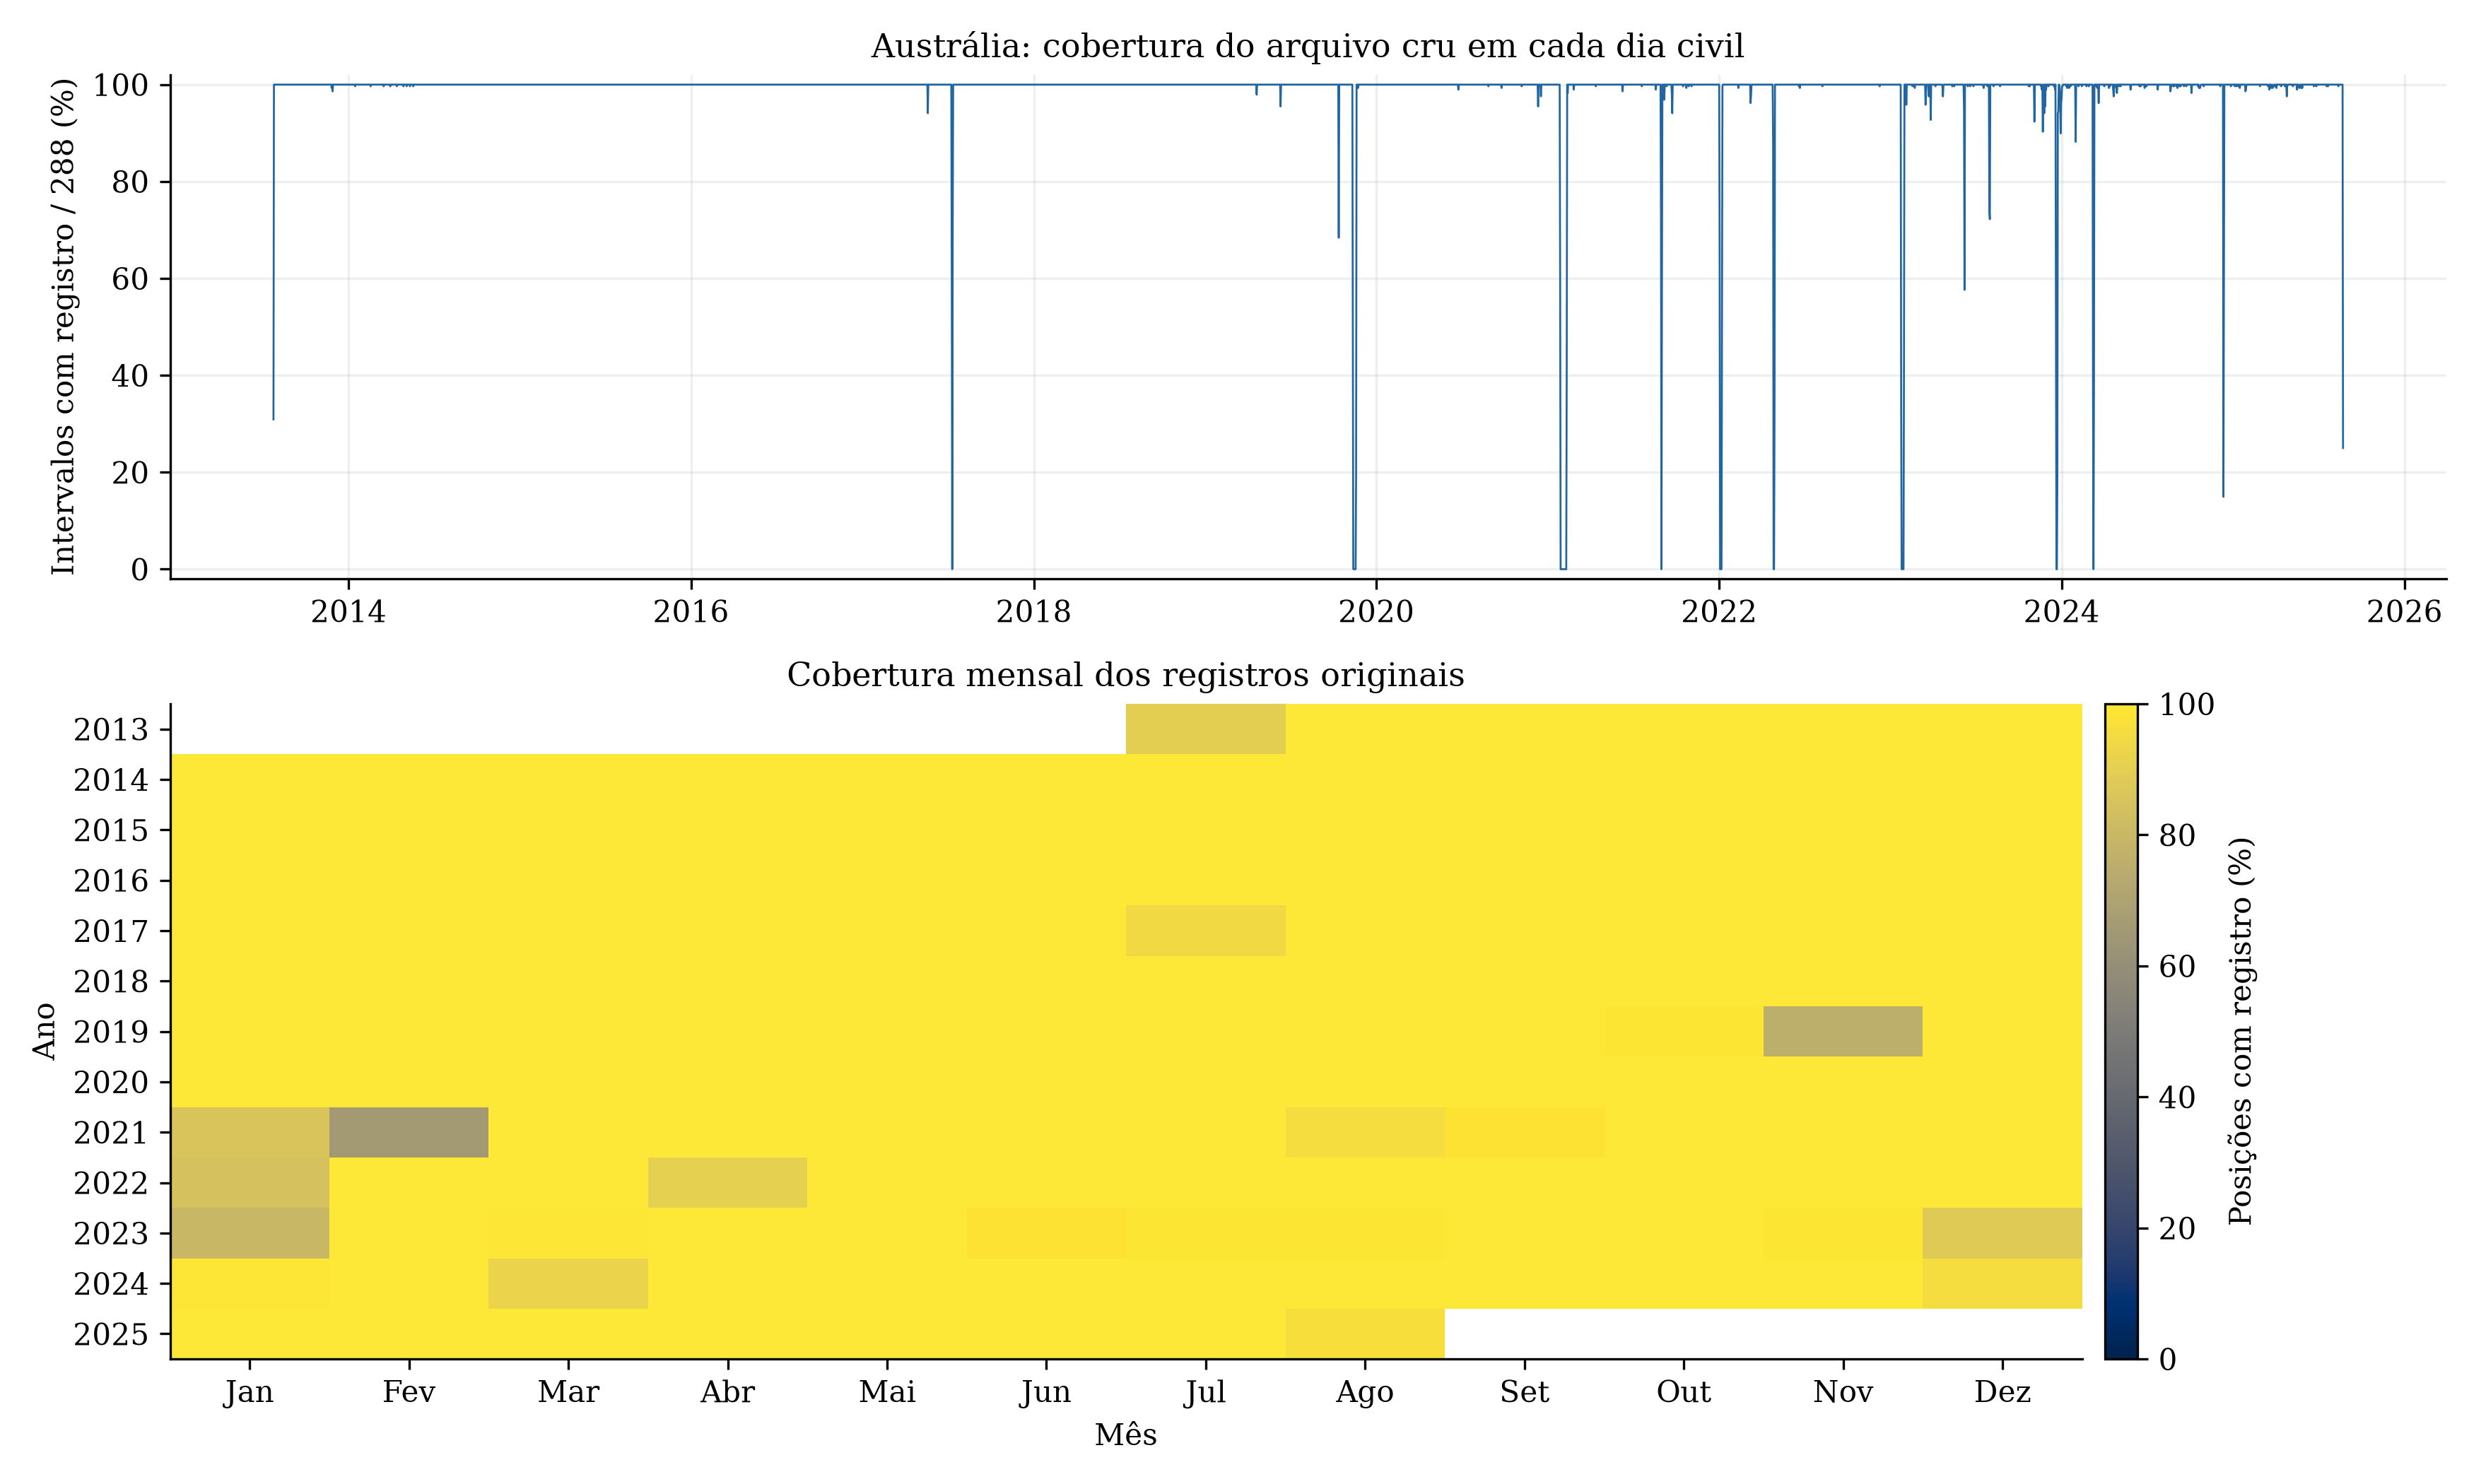

**Figura 3.2-01 — Disponibilidade do arquivo australiano integral.** Contagem de intervalos de cinco minutos com registros, sem filtro de valores ou imputação. Os timestamps australianos estão alinhados à grade exata. O período integral do arquivo é usado; não há corte em 2023. Dias civis completos são a referência, inclusive nas bordas parciais do arquivo. Branco: mês fora do intervalo.

Fonte: elaboração própria com os arquivos originais identificados no manifesto.

In [2]:
au = fontes["australia"]
campos = ["linhas_arquivo", "inicio_registrado", "fim_registrado", "dias_calendario",
          "timestamps_invalidos", "linhas_fora_grade_5min", "chaves_repetidas",
          "dias_sem_qualquer_registro", "dias_com_registros_parciais", "dias_com_grade_completa"]
display(pd.DataFrame({"Indicador": campos, "Valor": [au["meta"][c] for c in campos]}))
display(au["inventario"])
figura(1)

**Leitura da figura:** o painel superior localiza os dias com interrupções ou coleta parcial; o mapa mensal identifica períodos de menor cobertura no arquivo integral. Uma alta disponibilidade mensal pode ocultar interrupções curtas. O CSV `australia_por_dia.csv` permite identificar cada dia e sua cobertura sem alterar os dados crus.

## 3.2.2 Base de dados brasileira

Fontes originais: `Leopoldo-fixa-inv.csv` e `Leopoldo-fixa-est.csv`. Localização informada da usina: latitude −16,55°, longitude −48,85° e altitude 927 m.

Os arquivos têm estruturas diferentes: cada linha dos inversores se refere a um equipamento, enquanto a estação contém variáveis meteorológicas. A tabela seguinte explicita outros códigos de usina presentes no CSV antes de selecionar **07-07FX** para a caracterização. A seleção identifica a instalação estudada; não corrige seus registros.

Nesta etapa, os oito inversores são avaliados separadamente. Não se somam potências, não se comparam os contadores para aprovar dias e não se reconstroem alvos diários. Os campos de potência permanecem em W, e os de energia conservam a unidade kWh indicada pelos nomes originais.

Equipamentos selecionados: ['inverter121', 'inverter122', 'inverter123', 'inverter124', 'inverter125', 'inverter126', 'inverter127', 'inverter128']


,arquivo,codigo,linhas_no_arquivo
0,Brasil — inversores,07-07FX,733389
1,Brasil — inversores,07-07TK-2,60218
2,Brasil — estação,07-07FX,35535


,1,2
fonte,Brasil — inversores,Brasil — estação
linhas_arquivo,793607,35535
linhas_selecionadas,733389,35535
n_equipamentos,8,1
inicio_registrado,2025-01-02 20:38:27.603000,2025-01-03 12:13:41.334000
fim_registrado,2025-12-31 20:55:00,2025-12-31 20:55:00
dias_sem_qualquer_registro,19,225
dias_com_registros_parciais,340,140
dias_com_grade_completa,6,0


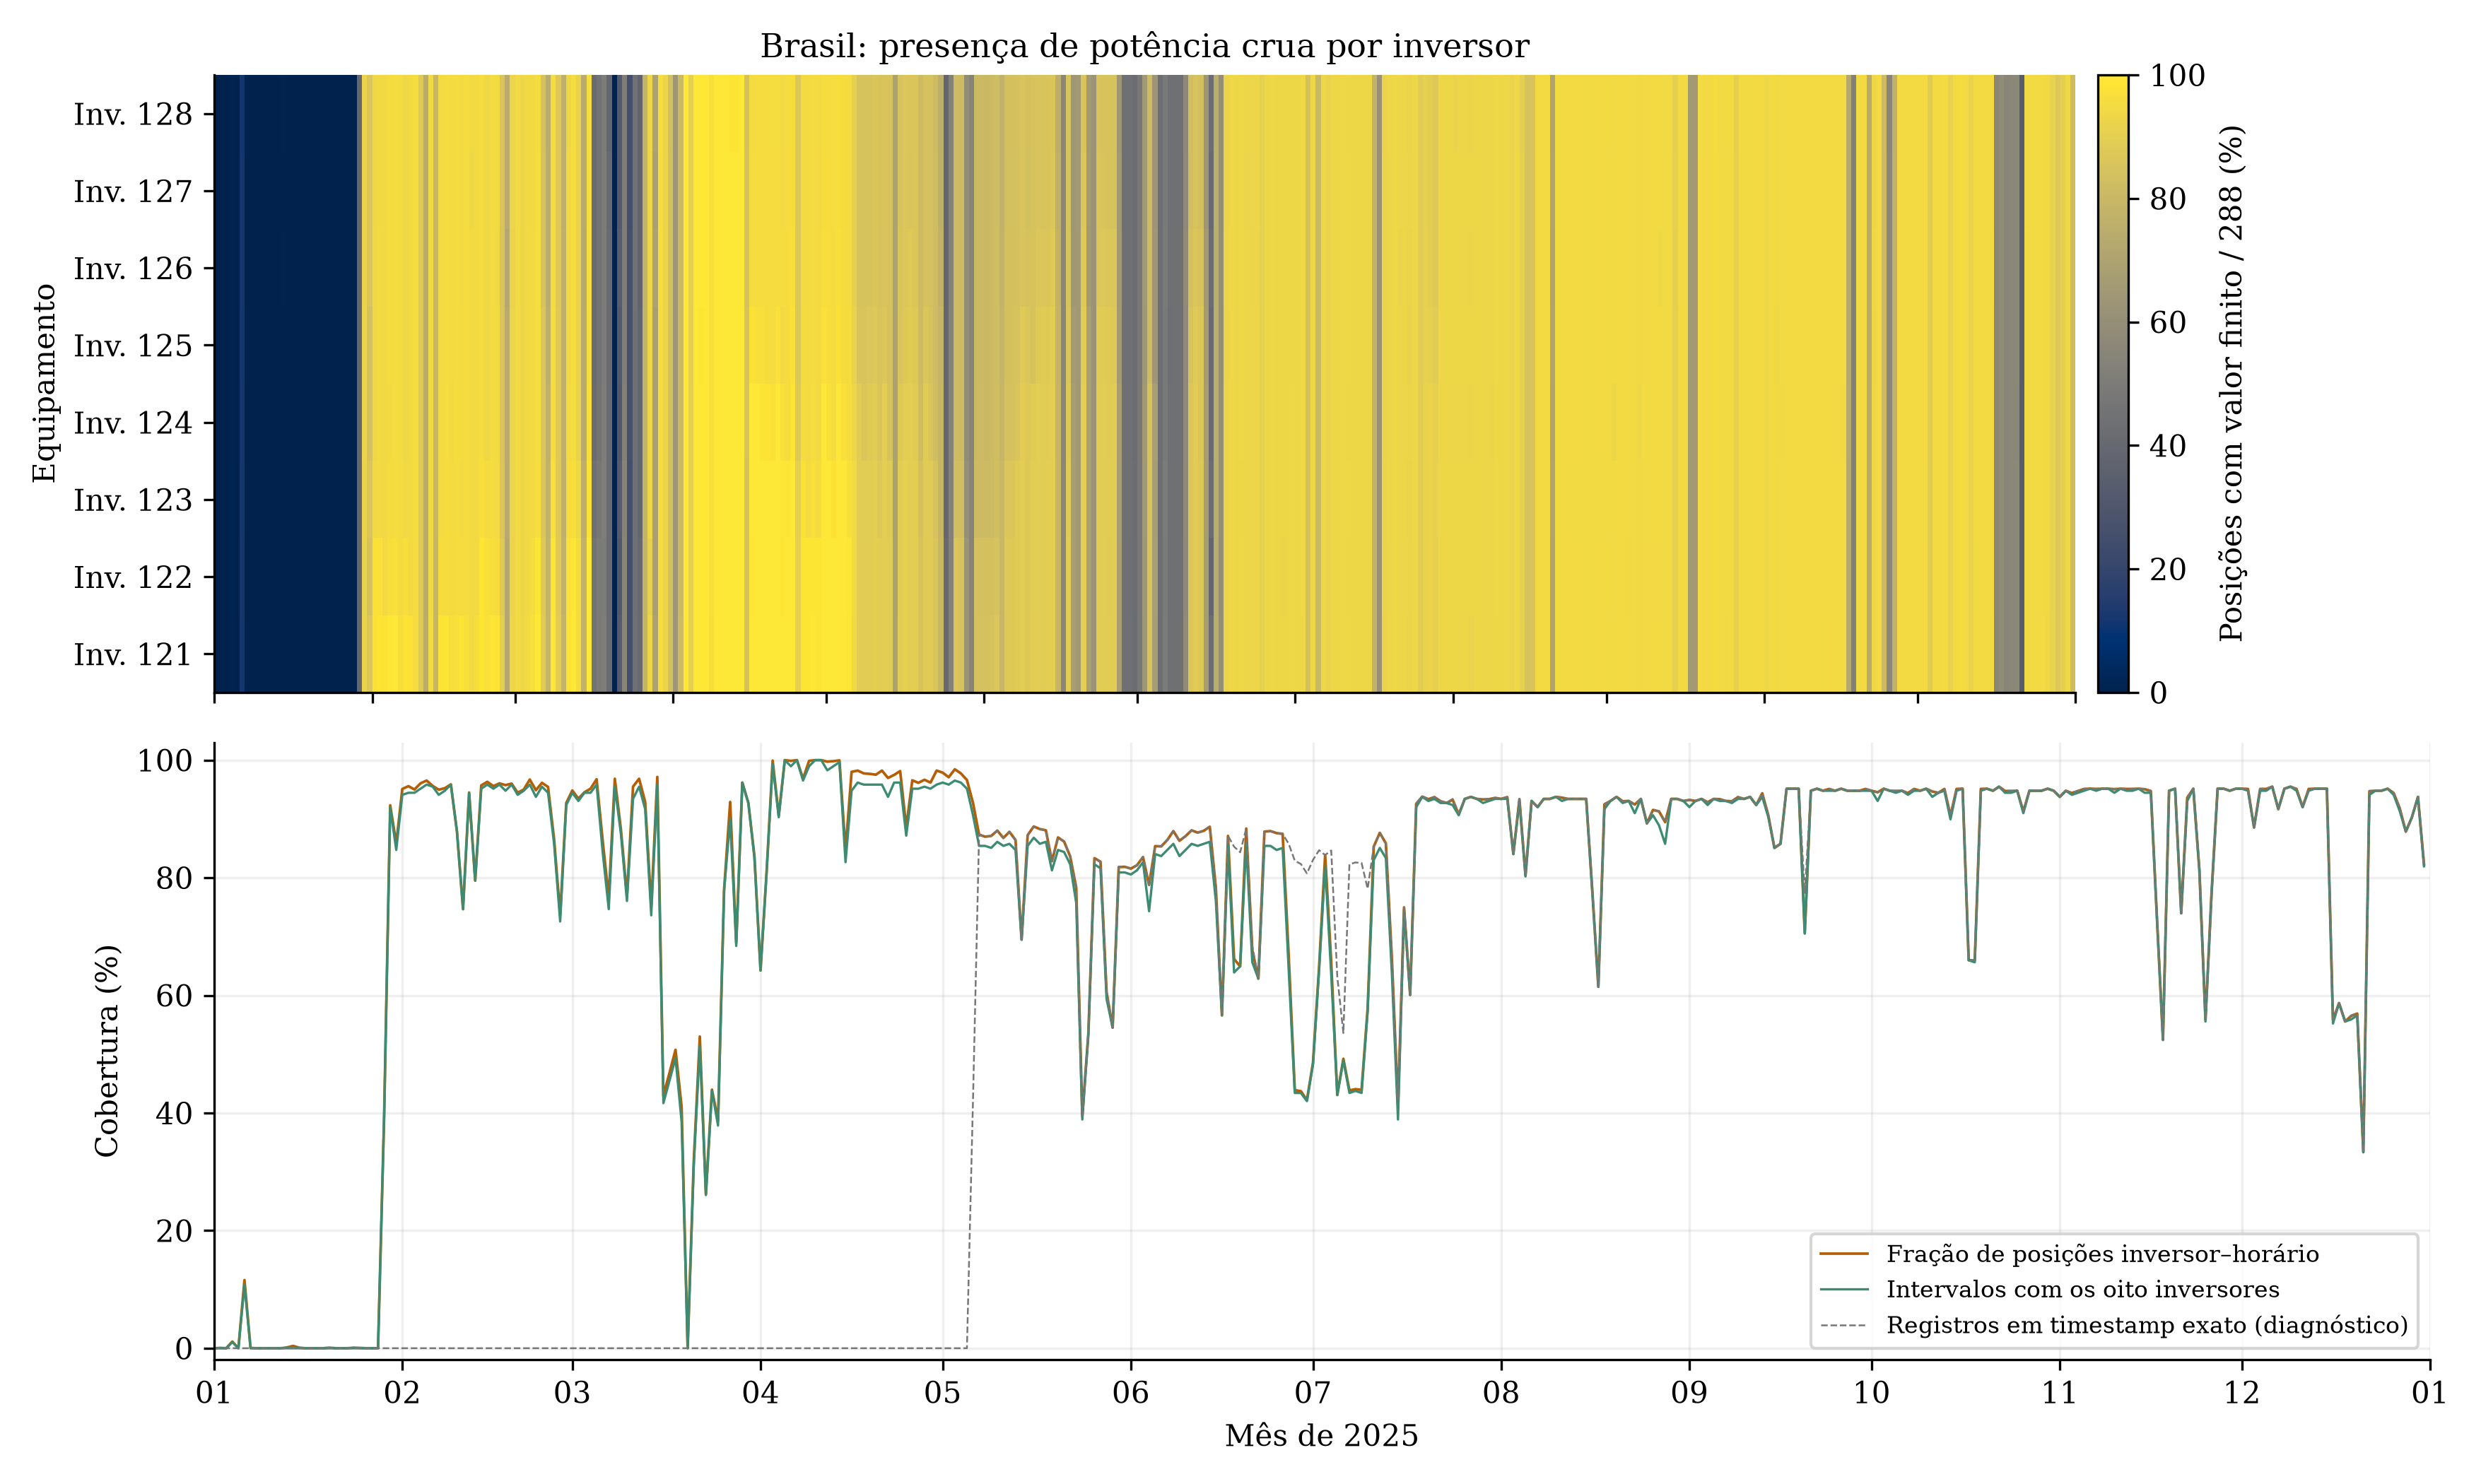

**Figura 3.2-02 — Disponibilidade dos registros crus dos inversores.** Código 07-07FX e datas locais de 2025. As curvas coloridas contam existência em intervalos [t,t+5min): 2304 posições inversor–intervalo por dia, ou 288 intervalos com os oito inversores presentes. A linha cinza exige timestamp exato e mostra o efeito do desalinhamento temporal; não implica ausência real de coleta. Presença no mesmo intervalo não exige o mesmo segundo. Nenhum valor ou timestamp cru é corrigido, somado ou imputado.

Fonte: elaboração própria com os arquivos originais identificados no manifesto.

In [3]:
inv = fontes["brasil_inversores"]
est = fontes["brasil_estacao"]
codigos = [{"arquivo": d["meta"]["fonte"], "codigo": codigo, "linhas_no_arquivo": n}
           for d in [inv, est] for codigo, n in d["meta"]["codigos_no_arquivo"].items()]
display(pd.DataFrame(codigos))
campos_br = ["fonte", "linhas_arquivo", "linhas_selecionadas", "n_equipamentos",
             "inicio_registrado", "fim_registrado", "dias_sem_qualquer_registro",
             "dias_com_registros_parciais", "dias_com_grade_completa"]
display(tabelas["resumo_fontes"].loc[lambda t: t.fonte.ne("Austrália"), campos_br].T)
print("Equipamentos selecionados:", inv["meta"]["equipamentos"])
figura(2)

### Estação meteorológica original

A temperatura e o GHI são analisados como constam do CSV local. Não se acrescentam ERA5 ou outra fonte externa. A estação não fornece uma coluna de umidade relativa no esquema disponível: isso é **ausência de variável**, e não deve ser contabilizado como perda de 100% das leituras de um sensor de umidade.

A escala de `ghi_irr_med` deve ser confirmada na documentação do sistema. O notebook mantém os números originais e não aplica multiplicação por 10 ou outra correção. As colunas totalmente vazias do inventário podem corresponder a campos de esquema sem instrumentação; não demonstram, por si só, defeito do sensor.

,coluna,linhas,ausentes_nas_linhas,ausentes_pct
0,datetime,35535,0,0.000
1,meta.id,35535,0,0.000
2,meta.id_usina,35535,0,0.000
3,meta.solar_station_id,35535,1494,4.204
4,indice_albedo_medio,35535,35535,100.000
...,...,...,...,...
59,poa_kwh_acc_est,35535,0,0.000
60,gri_irr_max,35535,34041,95.796
61,ghi_kwh_acc_est,35535,0,0.000
62,_id,35535,0,0.000


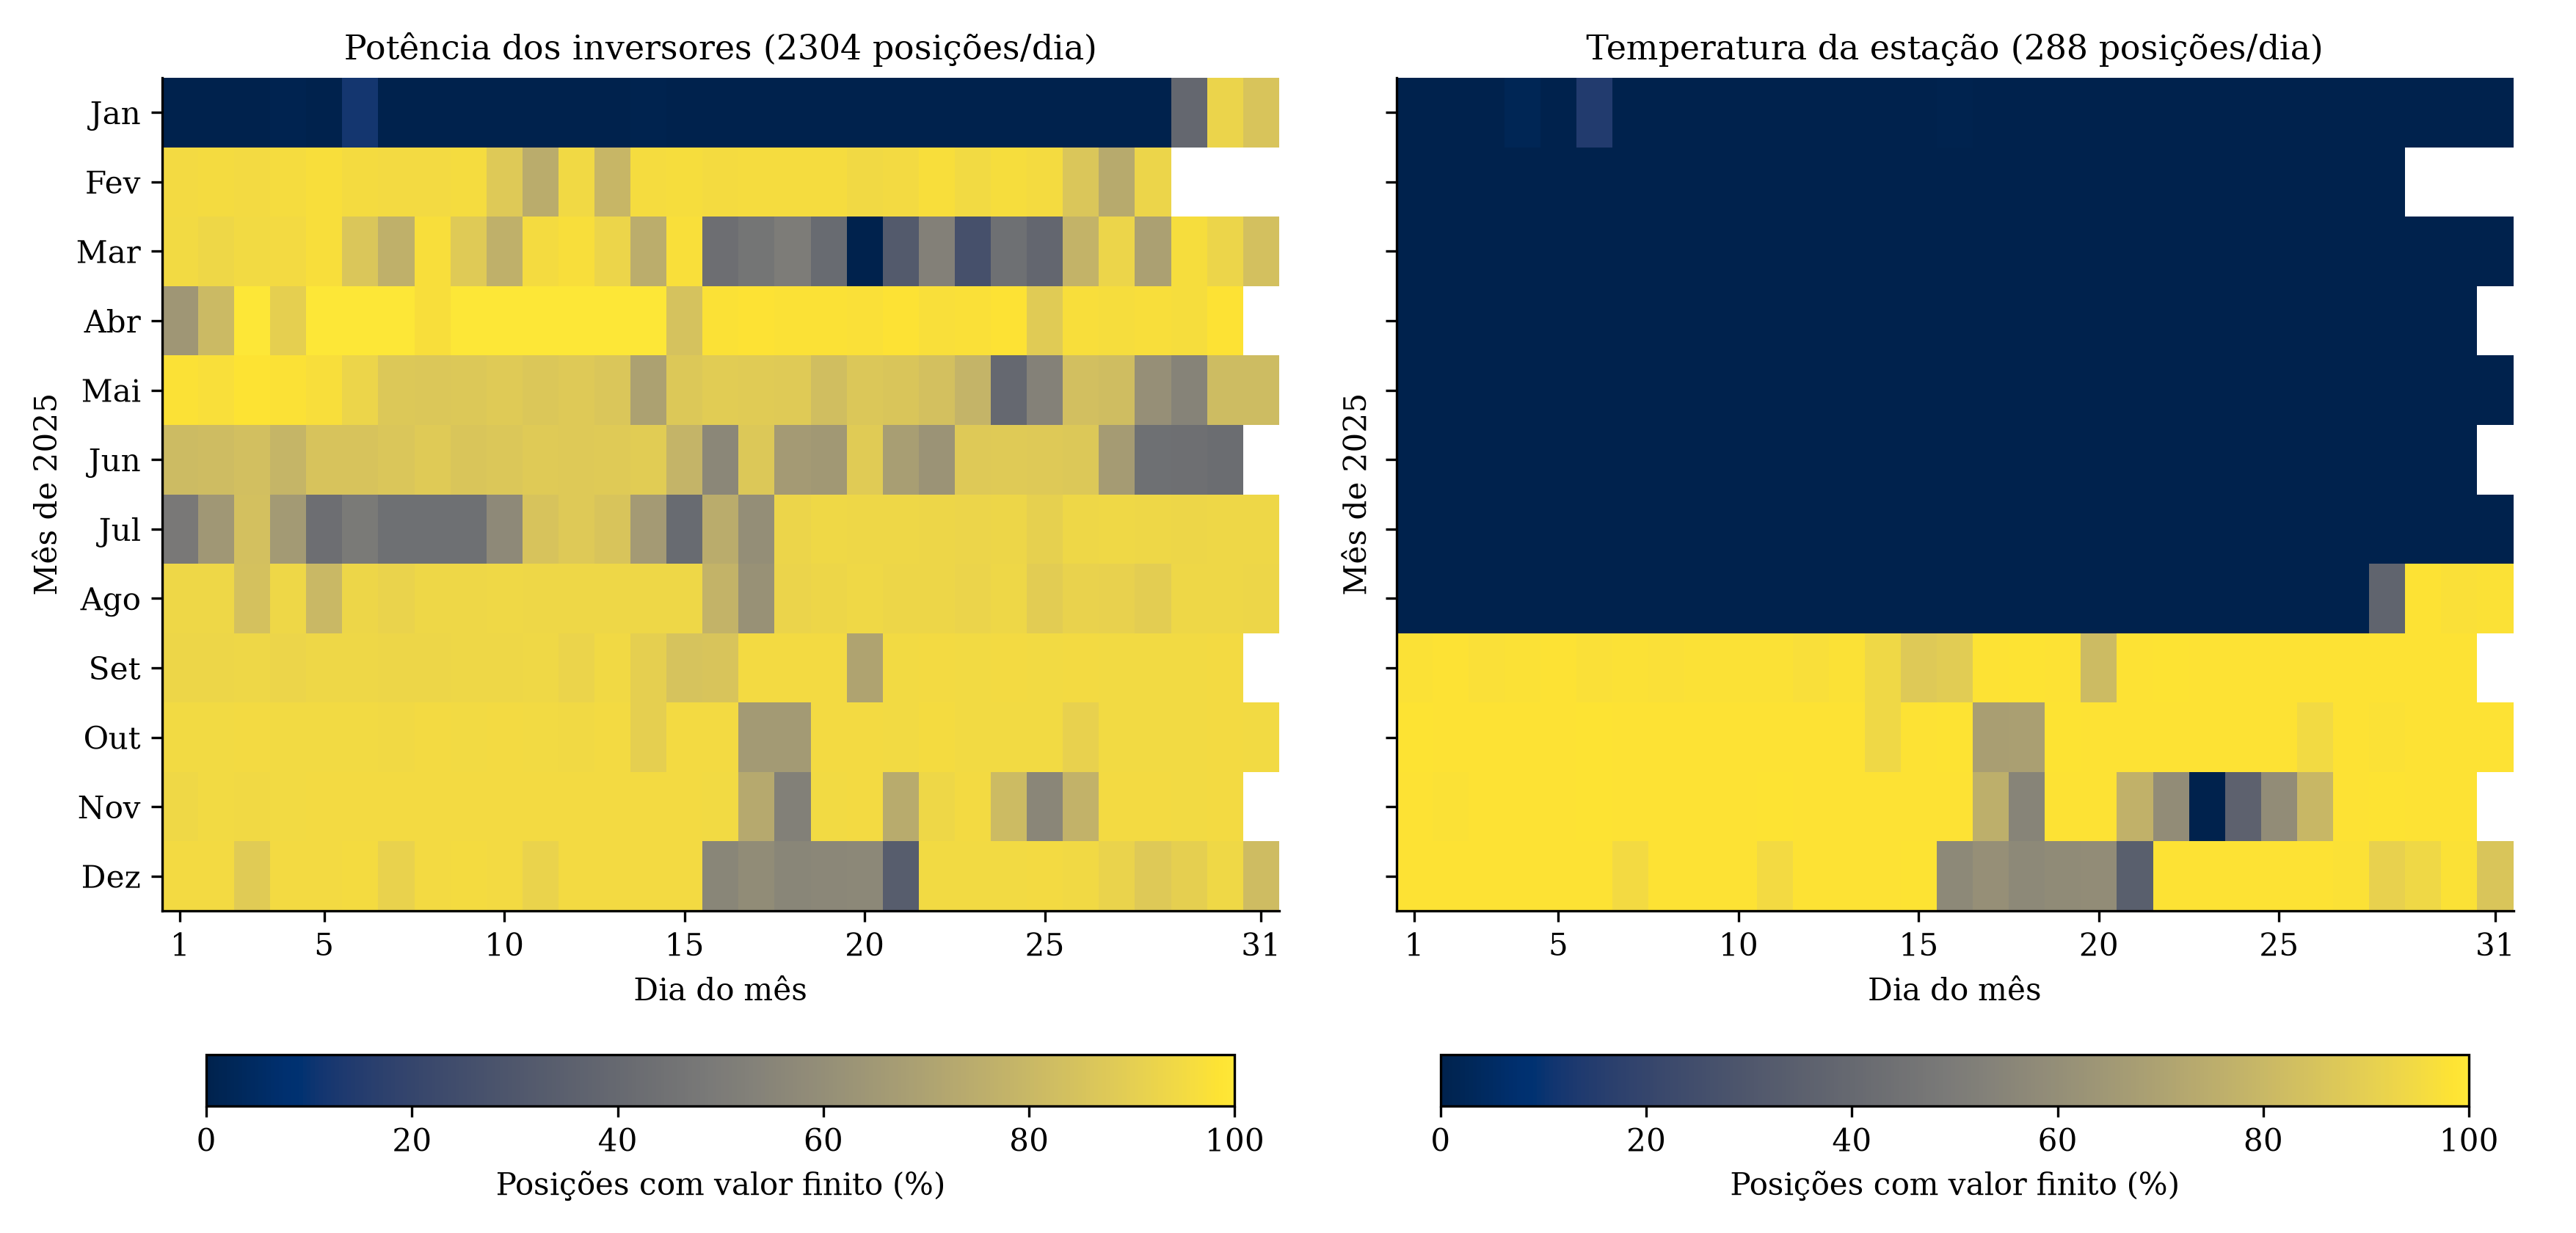

**Figura 3.2-03 — Calendário da disponibilidade original brasileira.** Ausências e coberturas parciais antes de qualquer reconstrução diária ou imputação. Zero significa nenhuma posição com valor finito da variável; branco indica dia inexistente no mês. A referência de calendário inclui dias sem aquisição e a borda final parcial do arquivo.

Fonte: elaboração própria com os arquivos originais identificados no manifesto.

In [4]:
display(est["inventario"])
figura(3)

## 3.2.3 Análise descritiva e disponibilidade dos dados

As estatísticas abaixo usam **todas as linhas originais selecionadas** com valores numéricos finitos, incluindo duplicatas, zeros, negativos e valores fora das faixas de triagem. Ausentes, textos não numéricos e infinitos são contados, mas não entram em médias, quantis e histogramas.

As distribuições possuem denominadores distintos: série australiana de vários anos, oito inversores brasileiros em 2025 e estação brasileira em 2025. Potência do sistema australiano em kW e potência individual dos inversores em W não representam a mesma grandeza operacional. Não há normalização por capacidade nesta etapa.

,fonte,variavel,linhas,n_finitos,vazios,texto_nao_numerico,infinitos,zeros,negativos,media,desvio_padrao,minimo,q25,mediana,q75,maximo
0,Austrália,Active_Power,1256431,1229605,26826,0,0,606646,18675,4.278,5.959,-0.062,0.000,0.000,8.079,23.426
1,Austrália,Weather_Temperature_Celsius,1256431,1224057,32374,0,0,5132,11932,21.185,10.081,-39.988,14.527,21.777,28.421,61.924
2,Austrália,Weather_Relative_Humidity,1256431,1224066,32365,0,0,5132,0,36.904,23.647,0.000,18.372,30.405,51.378,131.158
3,Austrália,Global_Horizontal_Radiation,1256431,1224105,32326,0,0,5132,1,264.931,364.322,-985.690,2.329,7.293,530.003,2015.182
4,Brasil — inversores,total_active_power_w,733389,719185,14204,0,0,378522,0,30041.657,43439.954,0.000,0.000,0.000,56301.000,128195.000
5,Brasil — inversores,daily_power_yields_kwh,733389,719185,14204,0,0,215718,0,338.900,327.619,0.000,0.000,282.900,652.600,1028.600
6,Brasil — inversores,total_power_yields_kwh,733389,719183,14206,0,0,51,0,267726.740,99528.378,0.000,208546.000,266366.000,348161.000,460575.000
7,Brasil — estação,air_temperature_med,35535,35535,0,0,0,0,0,23.522,4.789,11.613,19.845,22.465,27.259,36.465
8,Brasil — estação,ghi_irr_med,35535,35535,0,0,0,0,10987,39.750,106.928,-4.624,-0.094,1.538,56.745,1100.135


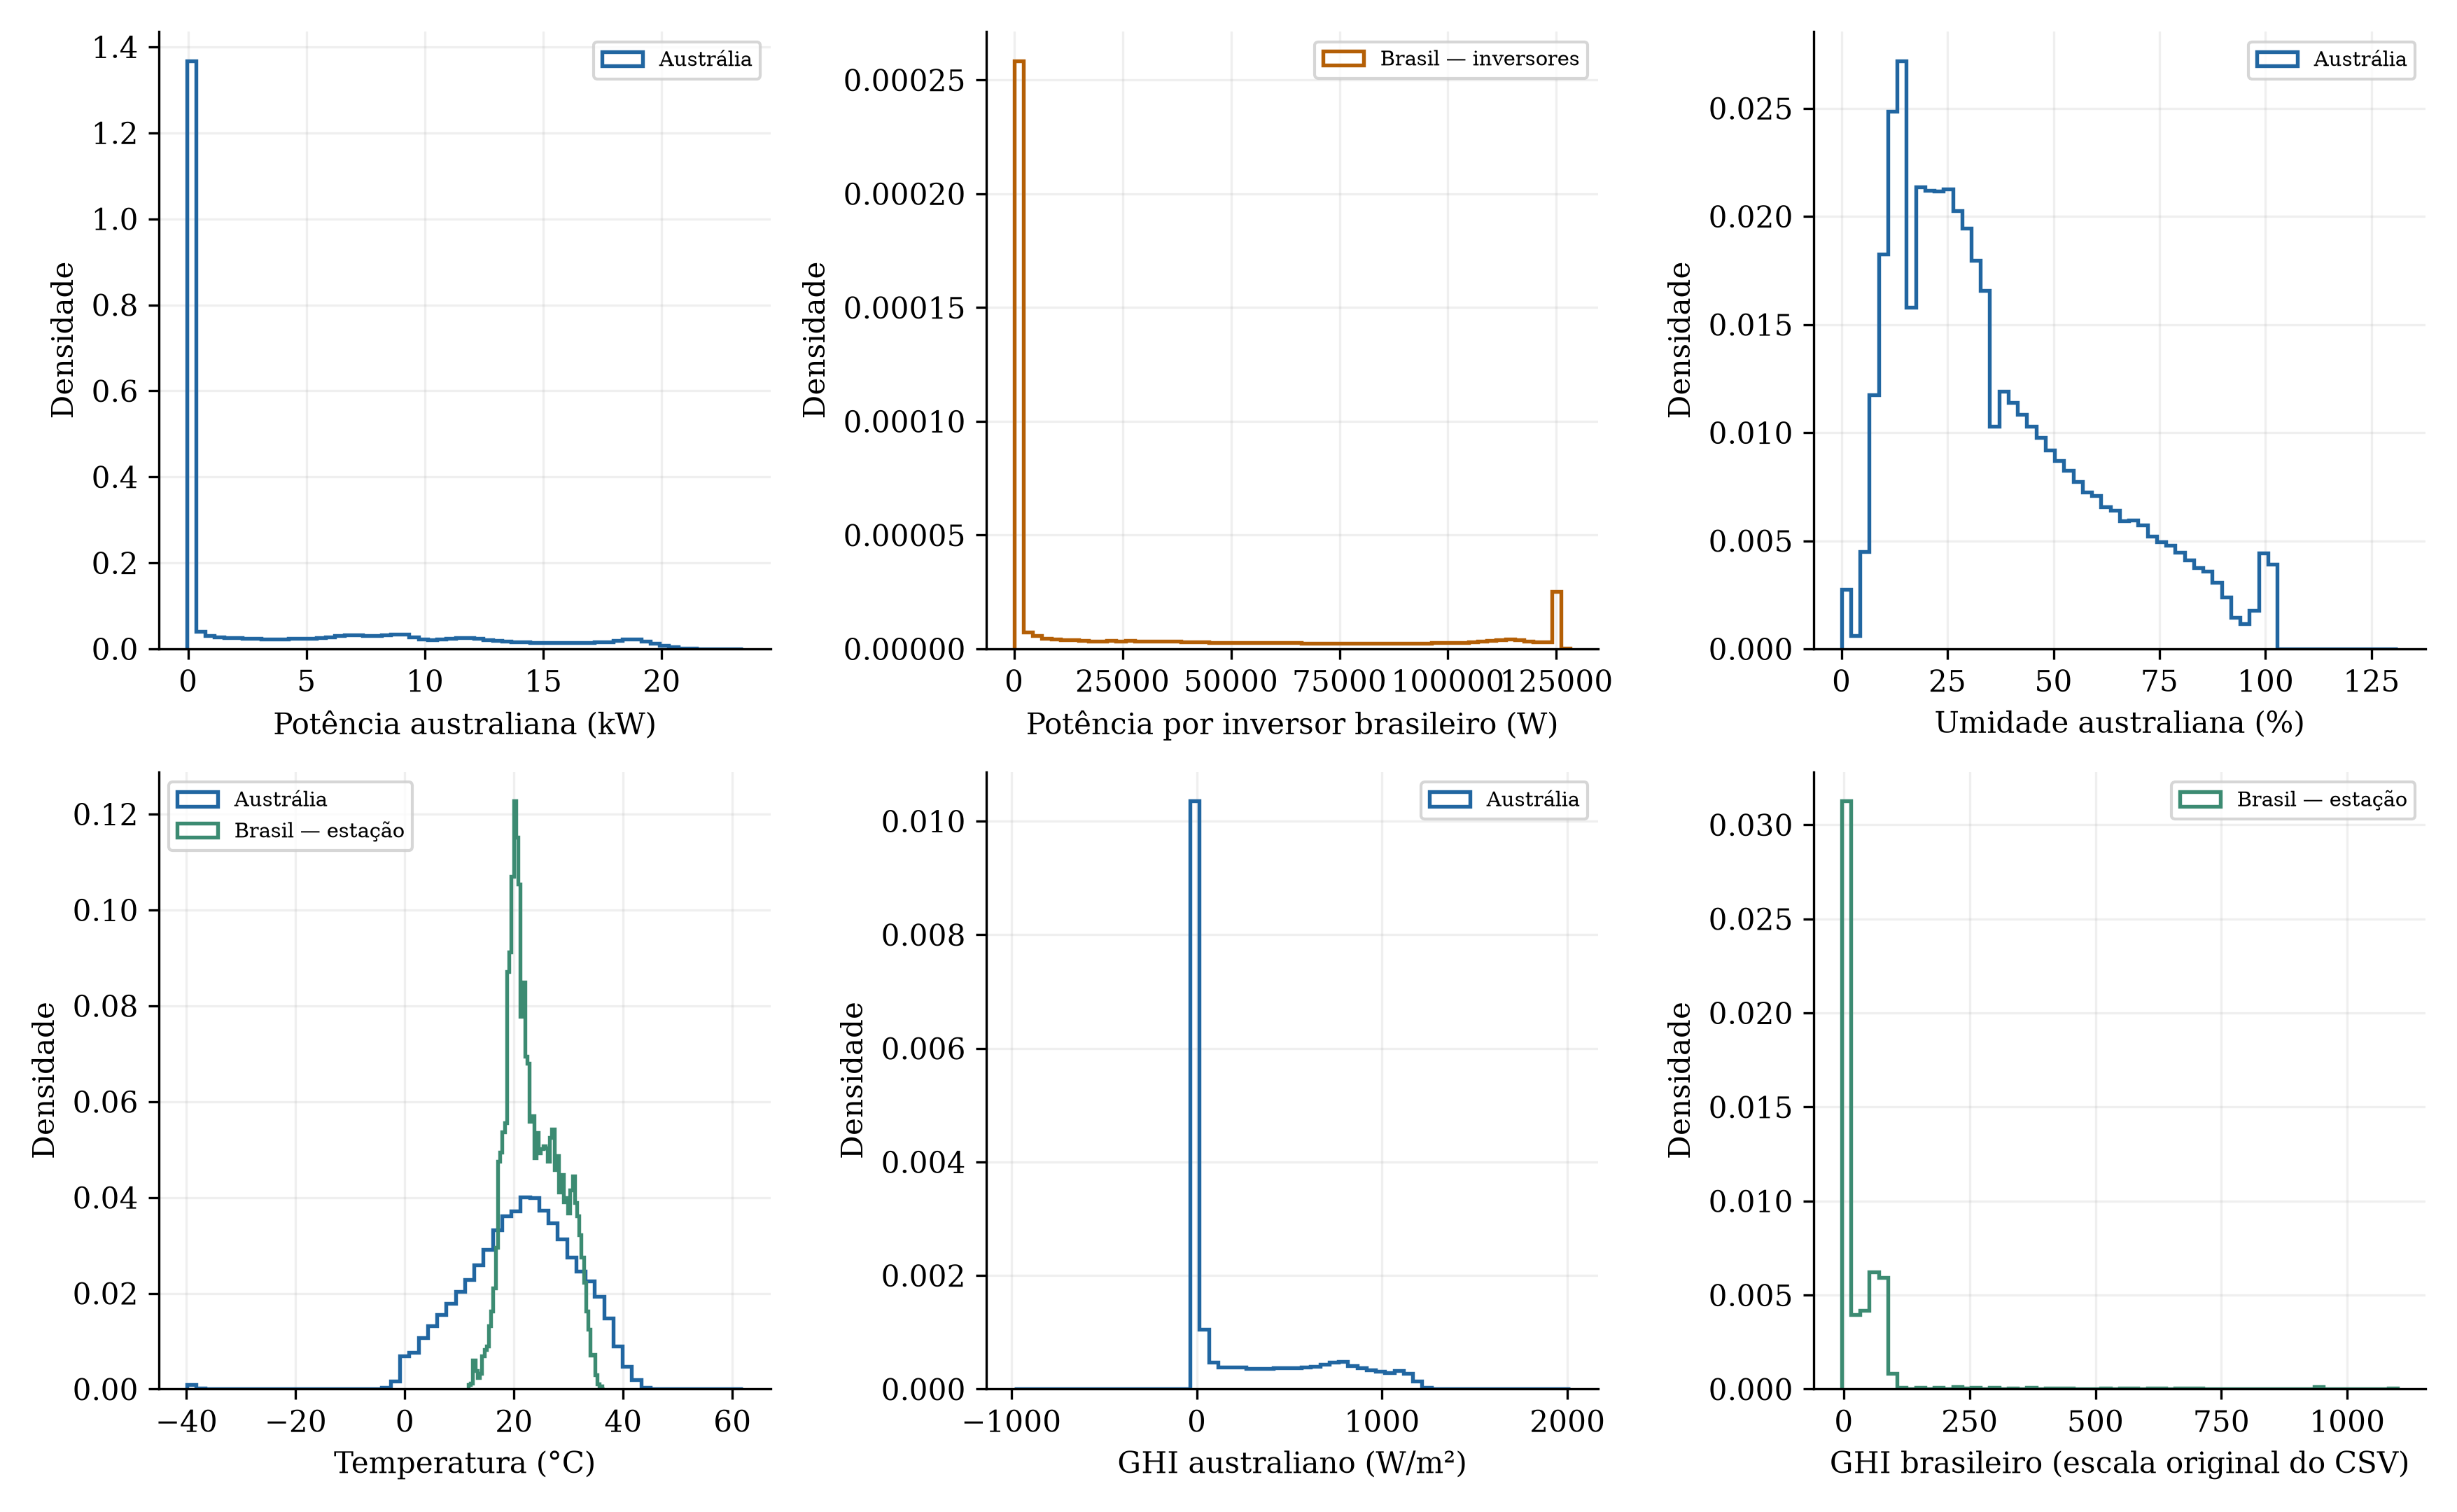

**Figura 3.2-05 — Distribuições dos valores originais registrados.** Todas as linhas com valores numéricos finitos entram, inclusive duplicatas e valores suspeitos. Não há normalização por capacidade, conversão da escala de GHI brasileira, remoção de negativos ou preenchimento. Potência brasileira é por inversor em W; australiana é a variável do sistema em kW. Infinitos e textos não numéricos ficam fora do histograma e são contados nas tabelas.

Fonte: elaboração própria com os arquivos originais identificados no manifesto.

In [5]:
colunas_estatisticas = ["fonte", "variavel", "linhas", "n_finitos", "vazios", "texto_nao_numerico",
                        "infinitos", "zeros", "negativos", "media", "desvio_padrao", "minimo", "q25", "mediana", "q75", "maximo"]
display(tabelas["estatisticas"][colunas_estatisticas])
figura(5)

### Disponibilidade na grade esperada

Para cada variável, a grade se divide em três categorias mutuamente exclusivas: sem registro; registro presente sem nenhum valor finito; e ao menos um valor finito presente. A fração indisponível é a soma das duas primeiras categorias. No caso dos inversores, uma posição é o par **intervalo de cinco minutos × equipamento**, evitando confundir a leitura de um inversor com a medição de toda a usina.

,fonte,variavel,esperados,sem_registro,registro_sem_valor_finito,com_valor_finito,indisponiveis_pct,vazios_nas_linhas,com_valor_finito_timestamp_exato
0,Austrália,Active_Power,1270944,14513,26826,1229605,3.253,26826,1229605
1,Austrália,Weather_Temperature_Celsius,1270944,14513,32374,1224057,3.689,32374,1224057
2,Austrália,Weather_Relative_Humidity,1270944,14513,32365,1224066,3.688,32365,1224066
3,Austrália,Global_Horizontal_Radiation,1270944,14513,32326,1224105,3.685,32326,1224105
4,Brasil — inversores,total_active_power_w,840960,160188,13008,667764,20.595,14204,472393
5,Brasil — inversores,daily_power_yields_kwh,840960,160188,13008,667764,20.595,14204,472393
6,Brasil — inversores,total_power_yields_kwh,840960,160188,13010,667762,20.595,14206,472391
7,Brasil — estação,air_temperature_med,105120,71737,0,33383,68.243,0,33321
8,Brasil — estação,ghi_irr_med,105120,71737,0,33383,68.243,0,33321


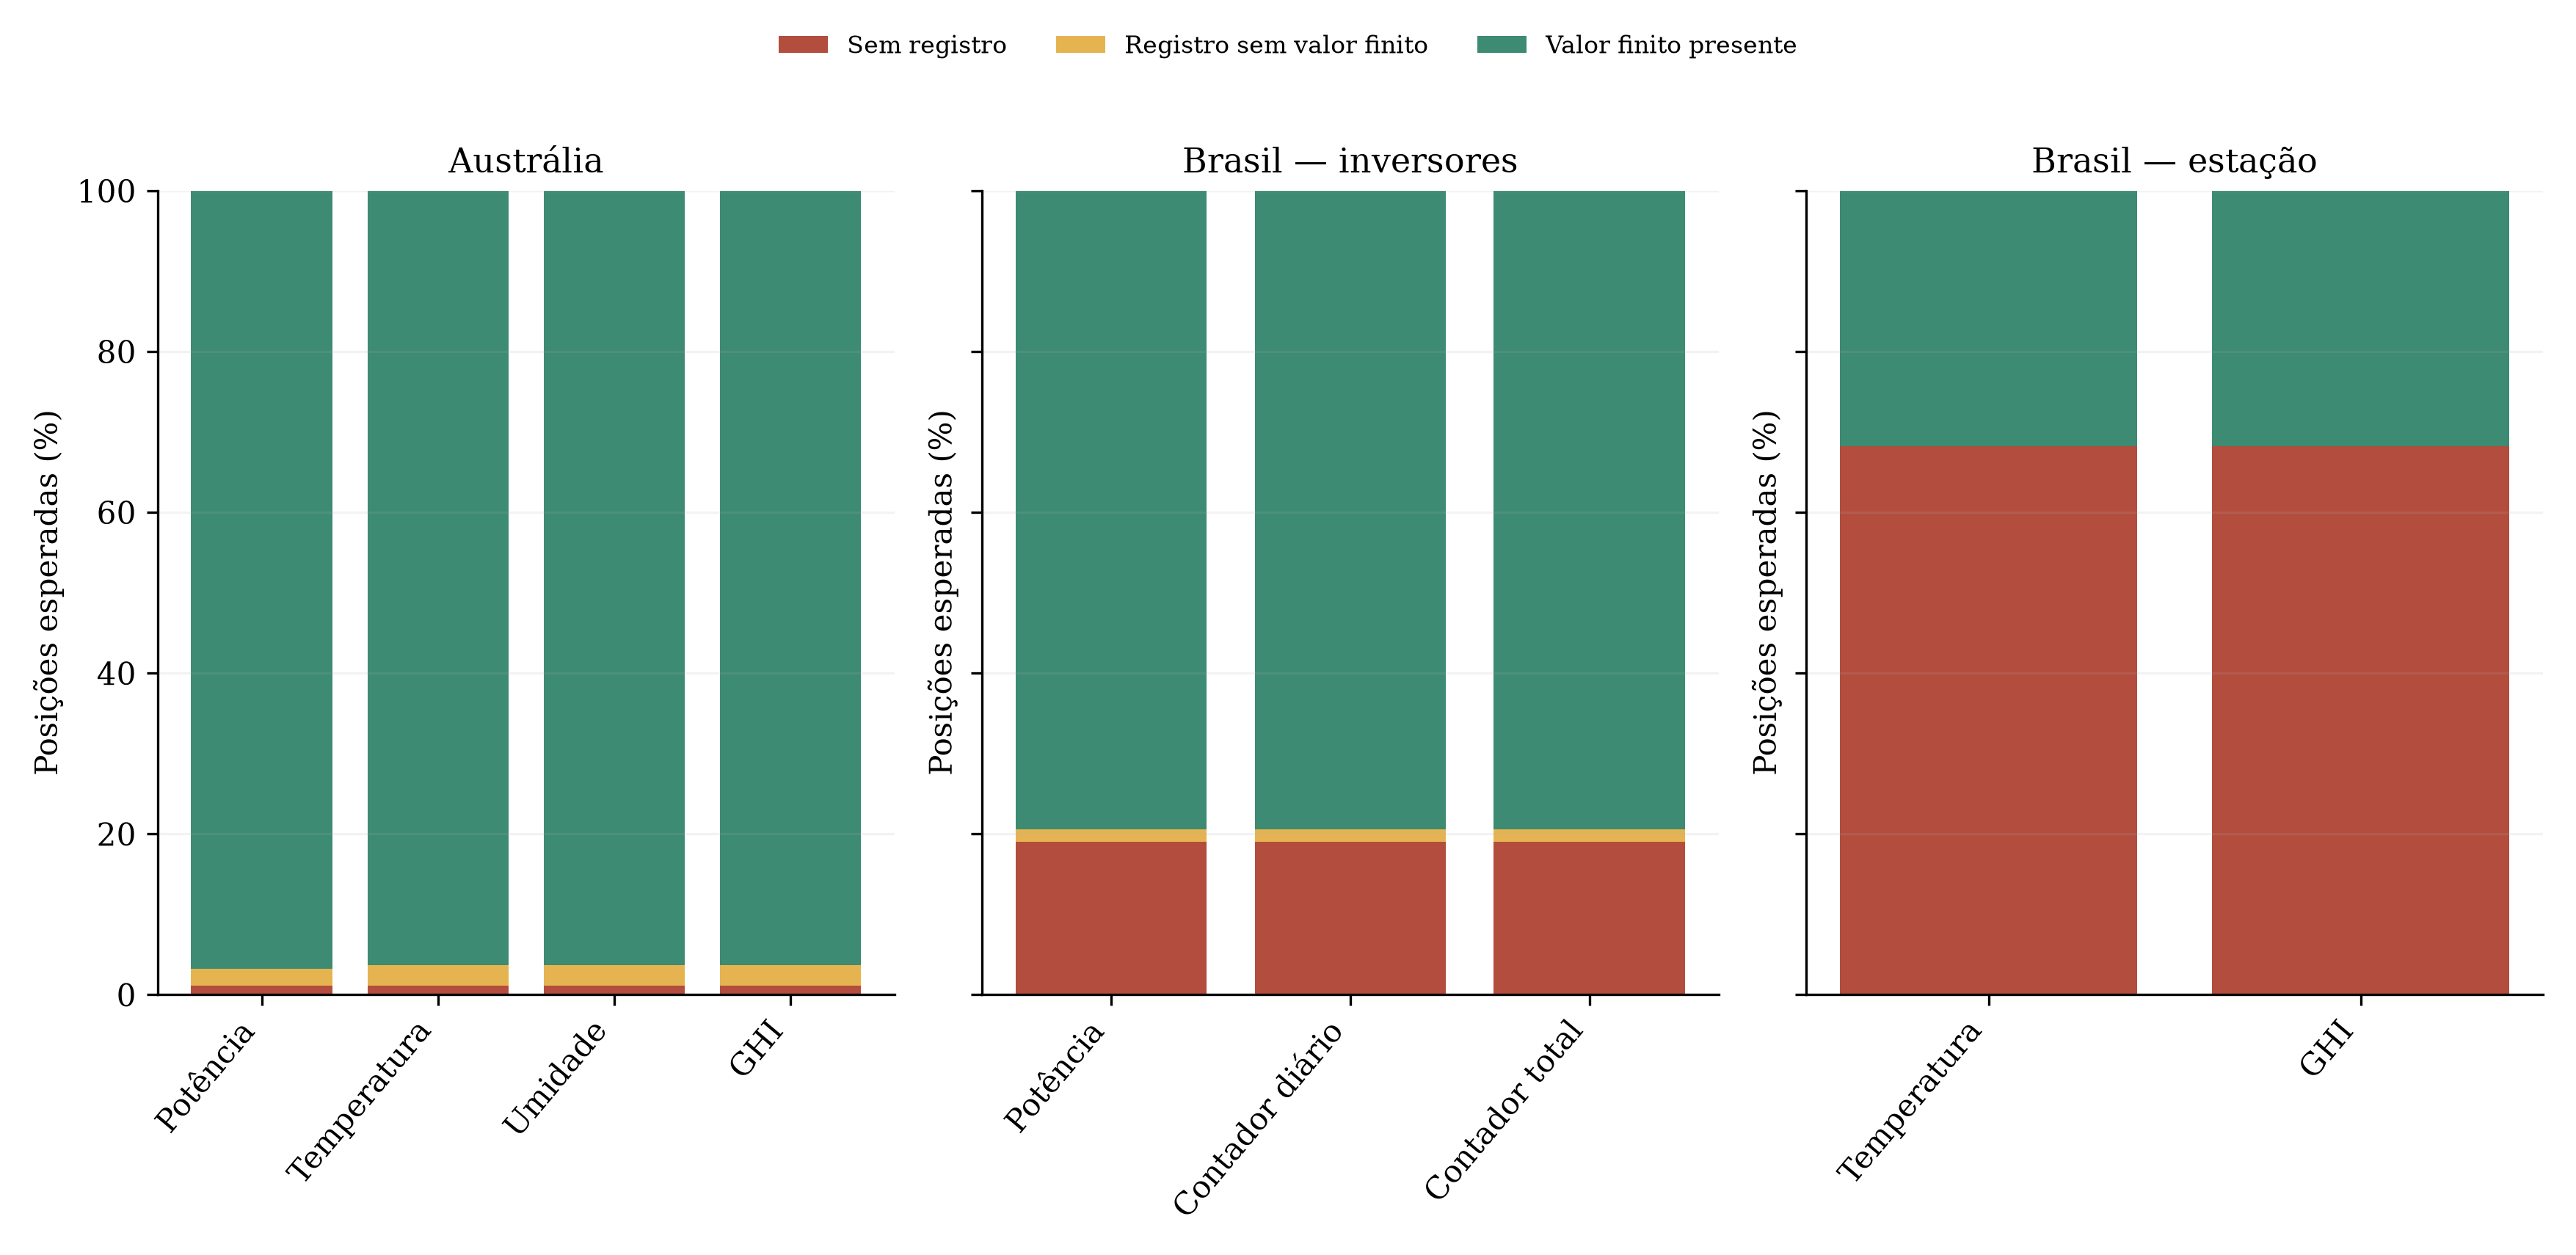

**Figura 3.2-04 — Ausência de registros e ausência de valores dentro dos registros.** Classes mutuamente exclusivas em intervalos [t,t+5min) por equipamento. Várias linhas no mesmo intervalo não multiplicam a cobertura: basta uma com valor finito. Valores finitos suspeitos, negativos ou fora das faixas de triagem continuam na classe verde; presença não equivale a validade. A classificação é uma contagem, sem consolidar valores ou modificar timestamps crus. As tabelas também mostram vazios nas linhas do CSV e timestamps exatos, com outras definições.

Fonte: elaboração própria com os arquivos originais identificados no manifesto.

In [6]:
display(tabelas["taxas"])
figura(4)

### Disponibilidade por mês e horário

A tabela mensal permite localizar os períodos com maiores perdas na coleta. O gráfico horário ajuda a avaliar se a ausência aparece principalmente em certas horas ou ao longo de todo o dia. O perfil é descritivo e não atribui causa às interrupções.

,fonte,mes,cobertura_registros_pct,cobertura_variavel_principal_pct
164,Brasil — estação,2025-07-01,0.000,0.000
161,Brasil — estação,2025-04-01,0.000,0.000
160,Brasil — estação,2025-03-01,0.000,0.000
163,Brasil — estação,2025-06-01,0.000,0.000
162,Brasil — estação,2025-05-01,0.000,0.000
159,Brasil — estação,2025-02-01,0.000,0.000
158,Brasil — estação,2025-01-01,0.694,0.694
146,Brasil — inversores,2025-01-01,7.474,7.451
165,Brasil — estação,2025-08-01,10.674,10.674
128,Austrália,2024-03-01,92.540,64.830


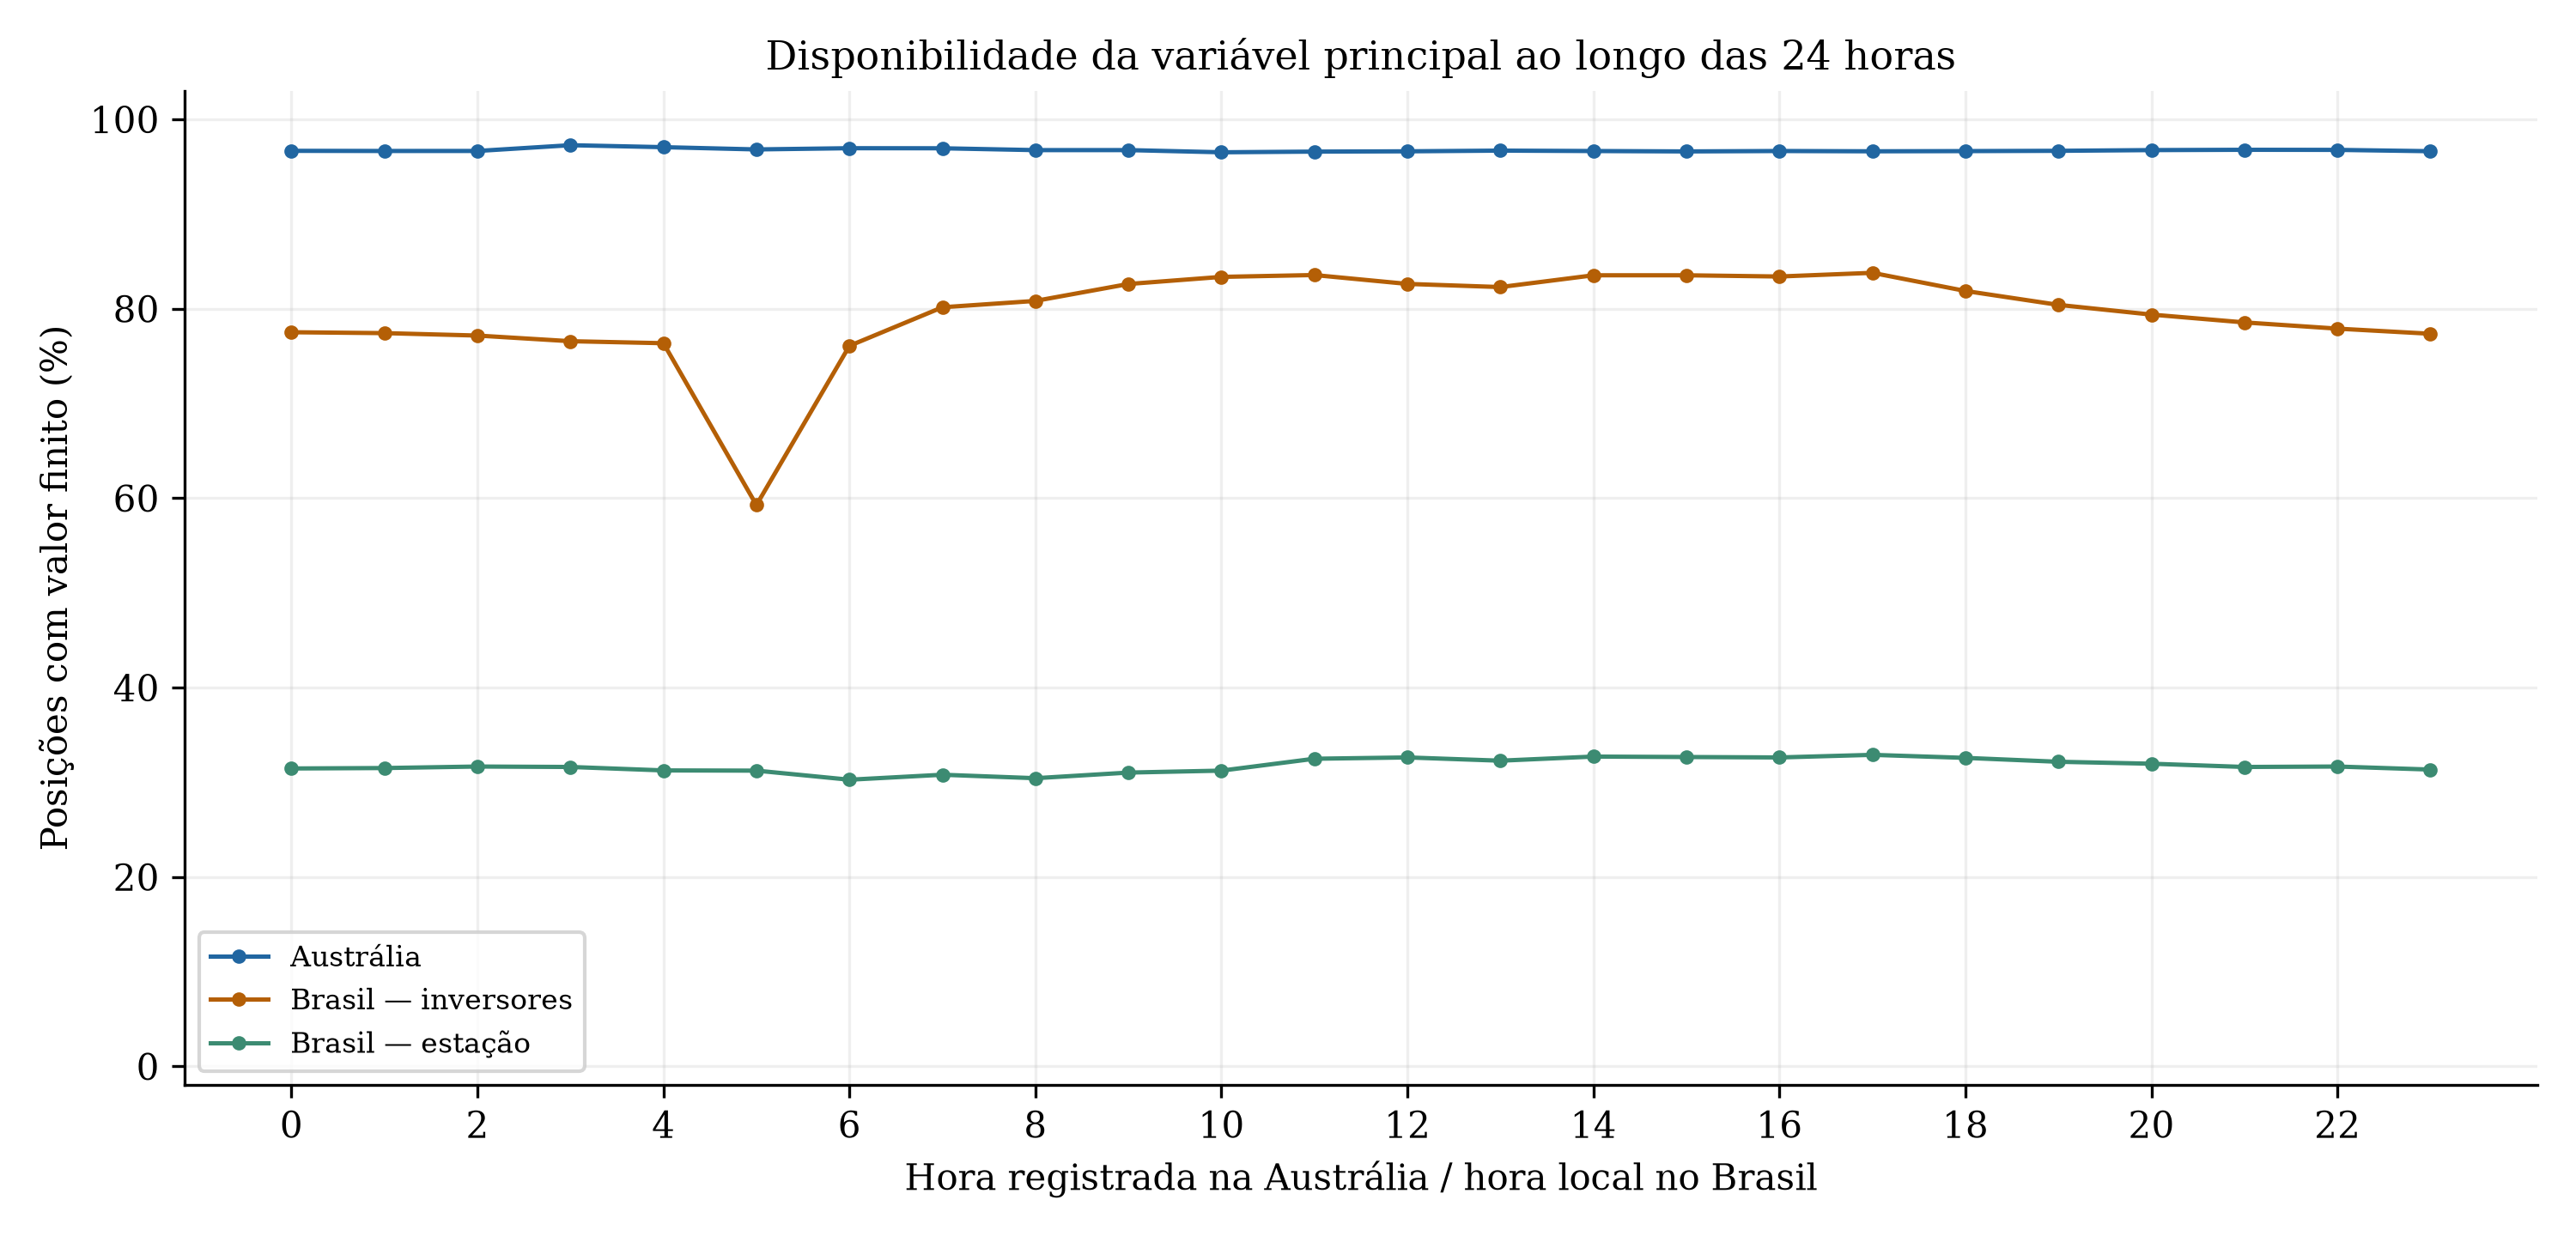

**Figura 3.2-09 — Perfil horário da disponibilidade original.** A grade considera as 24 horas. Zero de potência é um valor observado e não é marcado como faltante. Reduções noturnas de disponibilidade podem refletir política de aquisição; a figura não determina a causa. Austrália mantém a convenção temporal do arquivo sem fuso explícito; Brasil usa a apresentação local America/Sao_Paulo dos timestamps UTC.

Fonte: elaboração própria com os arquivos originais identificados no manifesto.

In [7]:
mensais = []
for chave, d in fontes.items():
    variavel = d["estatisticas"].variavel.iloc[0]
    diario = d["diario"]
    m = diario[["posicoes_esperadas", "posicoes_com_registro", f"posicoes_com_{variavel}"]].resample("MS").sum()
    m["cobertura_registros_pct"] = 100*m.posicoes_com_registro/m.posicoes_esperadas
    m["cobertura_variavel_principal_pct"] = 100*m[f"posicoes_com_{variavel}"]/m.posicoes_esperadas
    m["fonte"] = d["meta"]["fonte"]
    m.index.name = "mes"
    mensais.append(m.reset_index())
mensal = pd.concat(mensais, ignore_index=True)
mensal.to_csv(auditoria["tabelas_dir"] / "disponibilidade_mensal.csv", index=False)
display(mensal[["fonte", "mes", "cobertura_registros_pct", "cobertura_variavel_principal_pct"]]
        .sort_values("cobertura_variavel_principal_pct").head(20))
figura(9)

## 3.2.4 Identificação de dados ausentes e inconsistências

A investigação distingue ausência temporal de campo vazio, duplicatas, falhas de representação numérica e valores fora de faixas de triagem. A detecção não resulta em exclusão ou preenchimento.

Primeiro, avaliam-se os campos vazios nas linhas existentes. Esse diagnóstico isolado subestima as lacunas quando faltam linhas inteiras, razão pela qual a disponibilidade temporal também foi calculada.

,fonte,variavel,linhas,vazios,texto_nao_numerico,infinitos
0,Austrália,Active_Power,1256431,26826,0,0
1,Austrália,Weather_Temperature_Celsius,1256431,32374,0,0
2,Austrália,Weather_Relative_Humidity,1256431,32365,0,0
3,Austrália,Global_Horizontal_Radiation,1256431,32326,0,0
4,Brasil — inversores,total_active_power_w,733389,14204,0,0
5,Brasil — inversores,daily_power_yields_kwh,733389,14204,0,0
6,Brasil — inversores,total_power_yields_kwh,733389,14206,0,0
7,Brasil — estação,air_temperature_med,35535,0,0,0
8,Brasil — estação,ghi_irr_med,35535,0,0,0


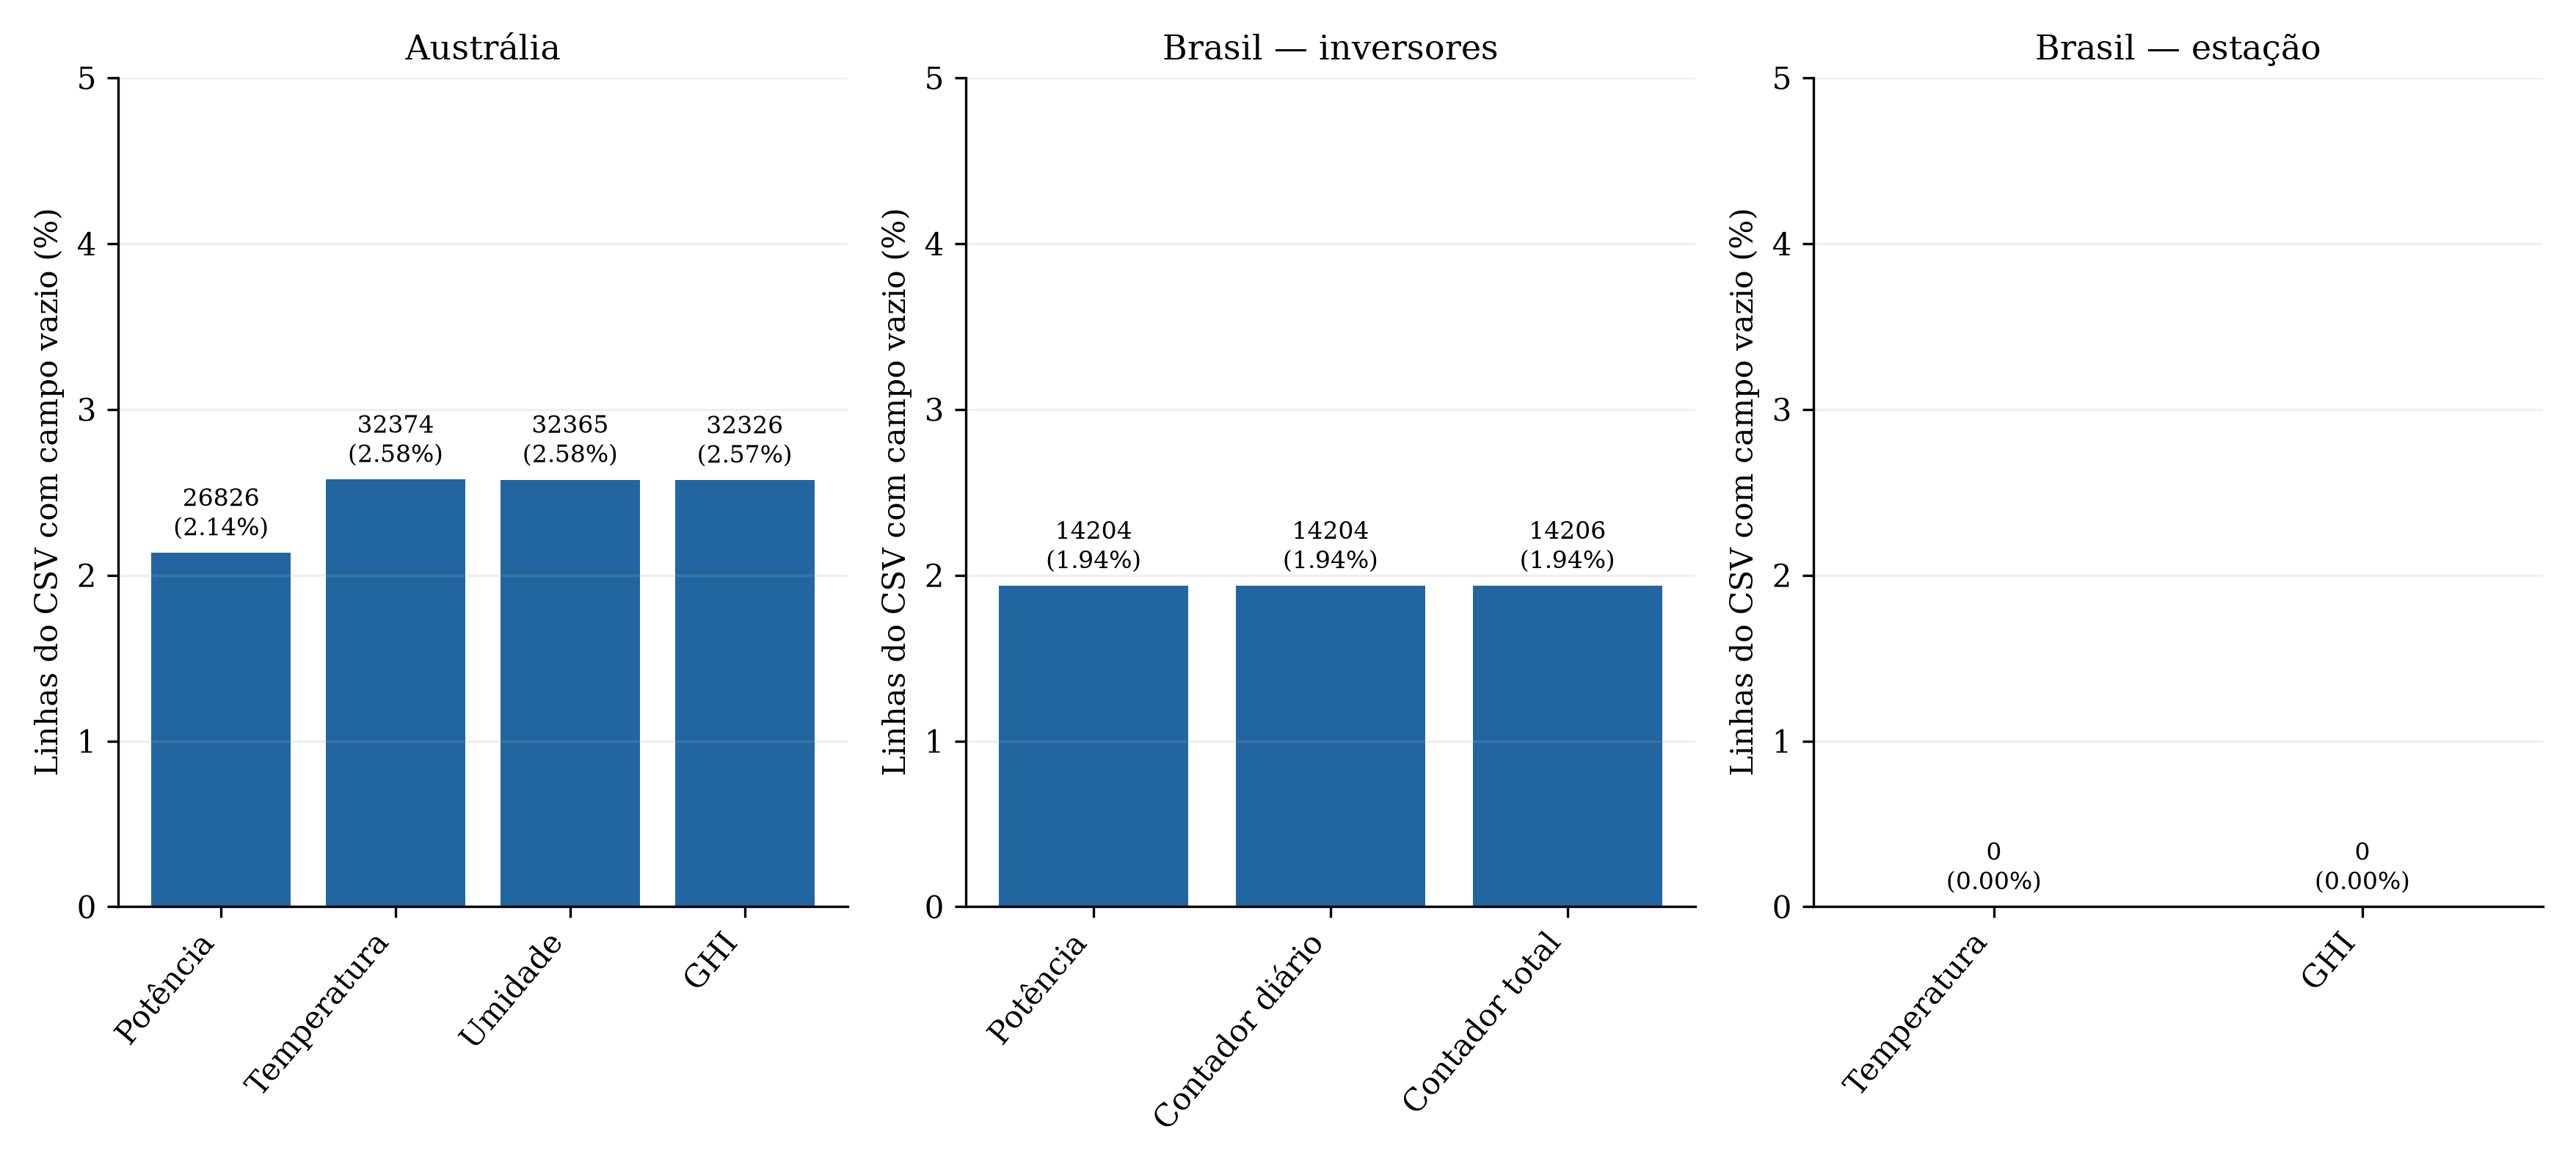

**Figura 3.2-06 — Campos vazios nas linhas presentes dos arquivos originais.** Denominador: linhas existentes na seleção de cada CSV, preservadas as duplicatas. Linhas inteiras que não foram registradas não entram aqui. Por isso, poucos NaN no arquivo podem coexistir com grandes lacunas temporais. Não há umidade no esquema da estação brasileira; essa variável não é adicionada artificialmente à contagem.

Fonte: elaboração própria com os arquivos originais identificados no manifesto.

In [8]:
display(tabelas["estatisticas"][["fonte", "variavel", "linhas", "vazios", "texto_nao_numerico", "infinitos"]])
figura(6)

### Duplicatas e valores suspeitos

Uma duplicata tem a mesma chave de timestamp e equipamento. O notebook informa chaves repetidas, linhas além da primeira e chaves com valores distintos em pelo menos um dos campos numéricos selecionados. Na última medida, uma diferença entre ausência e presença também conta como divergência. Não se presume que todas as colunas de duas linhas sejam idênticas.

Faixas de triagem: temperatura fora de −20 a 60 °C; umidade fora de 0 a 100%; valores negativos nos campos restantes selecionados. Esses limites identificam candidatos à inspeção, e não constituem uma comprovação automática de erro. Não é aplicado o limite diário de GHI aos registros de cinco minutos.

,fonte,timestamps_invalidos,equipamentos_ausentes,linhas_fora_grade_5min,linhas_fora_calendario,chaves_repetidas,linhas_excedentes_mesma_chave,chaves_com_valores_distintos
0,Austrália,0,0,0,0,0,0,0
1,Brasil — inversores,0,0,223941,0,7732,27422,10
2,Brasil — estação,0,0,1494,0,250,2144,180


,fonte,variavel,criterio,linhas_sinalizadas,denominador_linhas
0,Austrália,Active_Power,Valor negativo (triagem; não removido),18675,1256431
1,Austrália,Weather_Temperature_Celsius,Temperatura fora de −20 a 60 °C (triagem),3046,1256431
2,Austrália,Weather_Relative_Humidity,Umidade fora de 0 a 100%,14548,1256431
3,Austrália,Global_Horizontal_Radiation,Valor negativo (triagem; não removido),1,1256431
4,Brasil — inversores,total_active_power_w,Valor negativo (triagem; não removido),0,733389
5,Brasil — inversores,daily_power_yields_kwh,Valor negativo (triagem; não removido),0,733389
6,Brasil — inversores,total_power_yields_kwh,Valor negativo (triagem; não removido),0,733389
7,Brasil — estação,air_temperature_med,Temperatura fora de −20 a 60 °C (triagem),0,35535
8,Brasil — estação,ghi_irr_med,Valor negativo (triagem; não removido),10987,35535


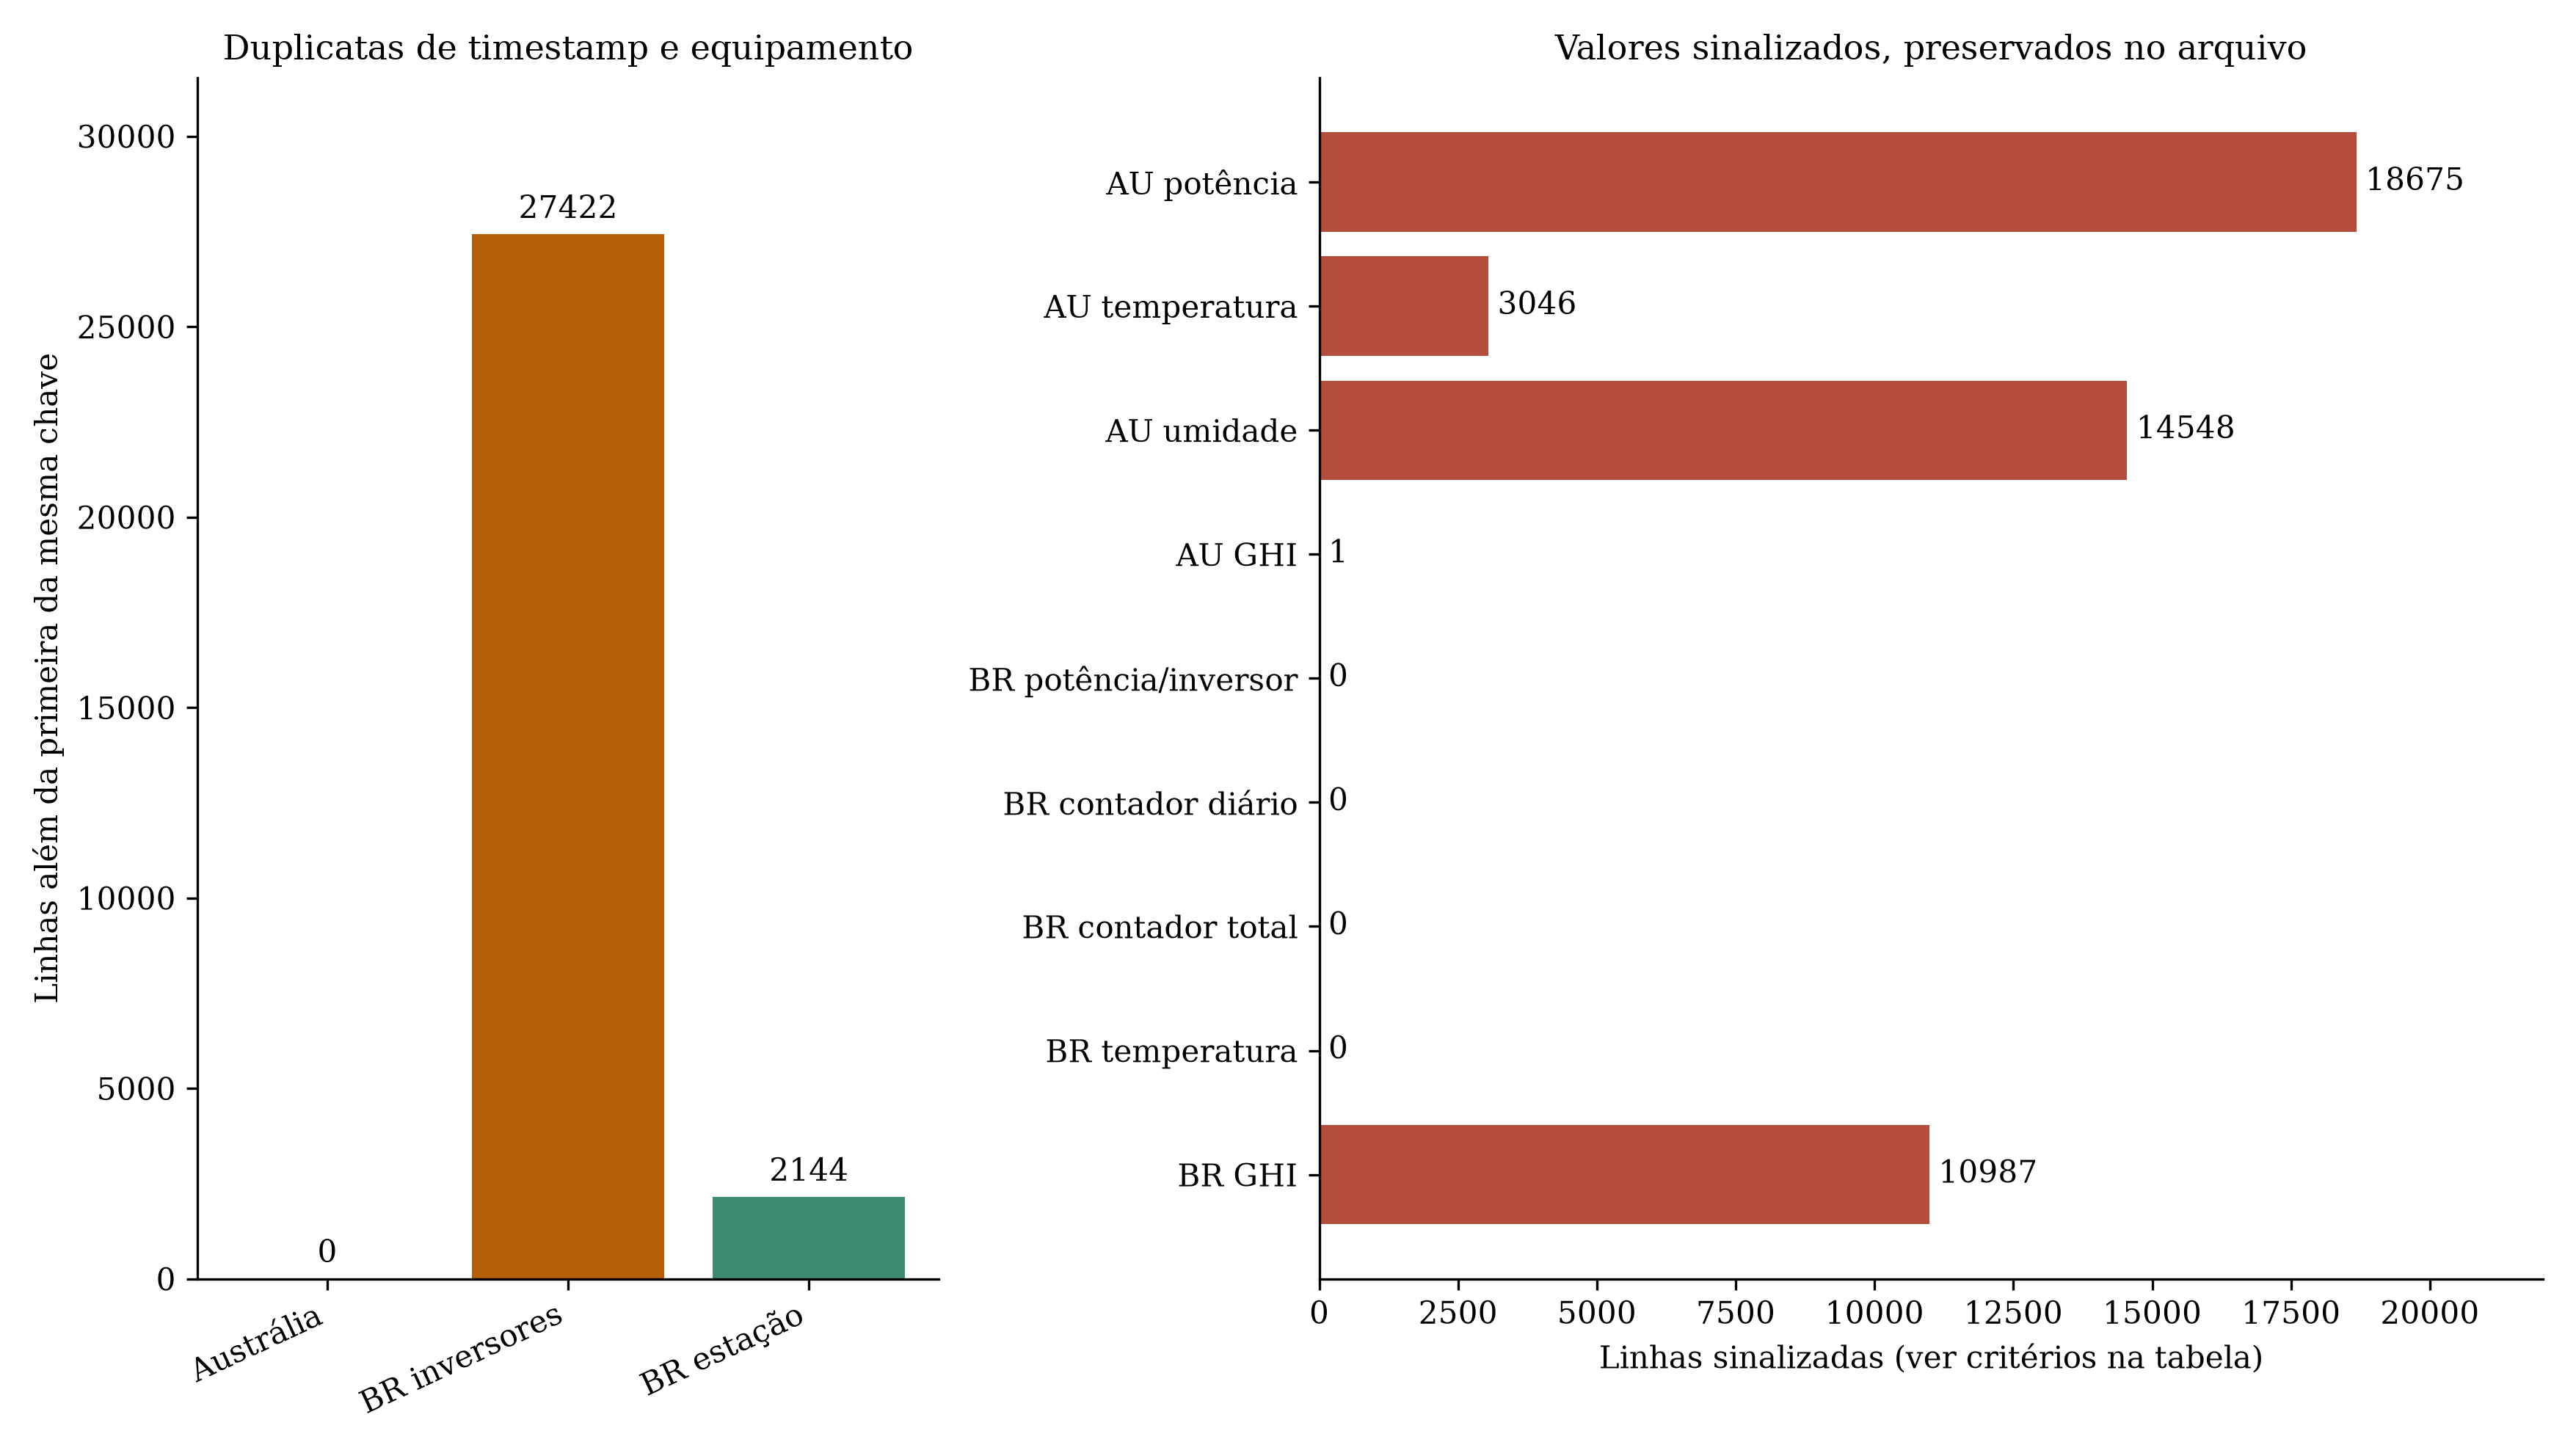

**Figura 3.2-07 — Duplicatas e sinais de inconsistência nos dados crus.** Duplicata significa mesma chave temporal e equipamento, não necessariamente linhas idênticas. Critérios de triagem: temperatura fora de −20 a 60 °C; umidade fora de 0 a 100%; negativos nos demais campos selecionados. Não se afirma que todo valor sinalizado seja erro de sensor e nenhum valor é removido. Divergência entre duplicatas é auditada nas tabelas, incluindo diferenças entre ausência e presença de valor.

Fonte: elaboração própria com os arquivos originais identificados no manifesto.

In [9]:
campos_qualidade = ["fonte", "timestamps_invalidos", "equipamentos_ausentes", "linhas_fora_grade_5min",
                    "linhas_fora_calendario", "chaves_repetidas", "linhas_excedentes_mesma_chave", "chaves_com_valores_distintos"]
display(tabelas["resumo_fontes"][campos_qualidade])
display(tabelas["flags"])
figura(7)

### Duração e localização das lacunas

As lacunas de intervalos de cinco minutos são calculadas por equipamento para a variável principal de cada fonte: potência australiana, potência de cada inversor brasileiro e temperatura da estação. A contagem de oito sequências de inversores não é diretamente comparável à de uma estação.

Também se identificam os intervalos de **dias civis inteiros sem qualquer registro** da fonte. Ausências nas bordas permanecem identificadas e precisam ser interpretadas à luz do início/fim da aquisição.

20 maiores lacunas de cinco minutos:
Períodos de dias inteiros sem qualquer registro:


,inicio,fim,posicoes,minutos,fonte,equipamento,variavel
56221,2025-01-31 13:00:00,2025-08-28 14:40:00,60213,301065.000,Brasil — estação,est_sols1,air_temperature_med
45872,2025-01-14 15:00:00,2025-01-29 14:10:00,4311,21555.000,Brasil — inversores,inverter127,total_active_power_w
25091,2025-01-14 15:05:00,2025-01-29 14:10:00,4310,21550.000,Brasil — inversores,inverter123,total_active_power_w
30257,2025-01-14 15:05:00,2025-01-29 14:10:00,4310,21550.000,Brasil — inversores,inverter124,total_active_power_w
51038,2025-01-15 12:25:00,2025-01-29 14:10:00,4054,20270.000,Brasil — inversores,inverter128,total_active_power_w
27,2021-01-27 14:10:00,2021-02-10 14:15:00,4034,20170.000,Austrália,sistema,Active_Power
35440,2025-01-06 13:55:00,2025-01-20 13:10:00,4024,20120.000,Brasil — inversores,inverter125,total_active_power_w
19972,2025-01-14 15:05:00,2025-01-25 21:05:00,3241,16205.000,Brasil — inversores,inverter122,total_active_power_w
14887,2025-01-14 15:05:00,2025-01-24 13:35:00,2863,14315.000,Brasil — inversores,inverter121,total_active_power_w
40675,2025-01-20 13:20:00,2025-01-29 14:10:00,2603,13015.000,Brasil — inversores,inverter126,total_active_power_w


,inicio,fim,posicoes,minutos,dias,fonte
0,2017-07-11,2017-07-11,1,1440.000,1,Austrália
1,2019-11-13,2019-11-18,6,8640.000,6,Austrália
2,2021-01-28,2021-02-09,13,18720.000,13,Austrália
3,2021-08-31,2021-08-31,1,1440.000,1,Austrália
4,2022-01-03,2022-01-06,4,5760.000,4,Austrália
5,2022-04-27,2022-04-28,2,2880.000,2,Austrália
6,2023-01-25,2023-01-29,5,7200.000,5,Austrália
7,2023-12-21,2023-12-22,2,2880.000,2,Austrália
8,2024-03-09,2024-03-09,1,1440.000,1,Austrália
17,2025-01-01,2025-01-02,2,2880.000,2,Brasil — estação


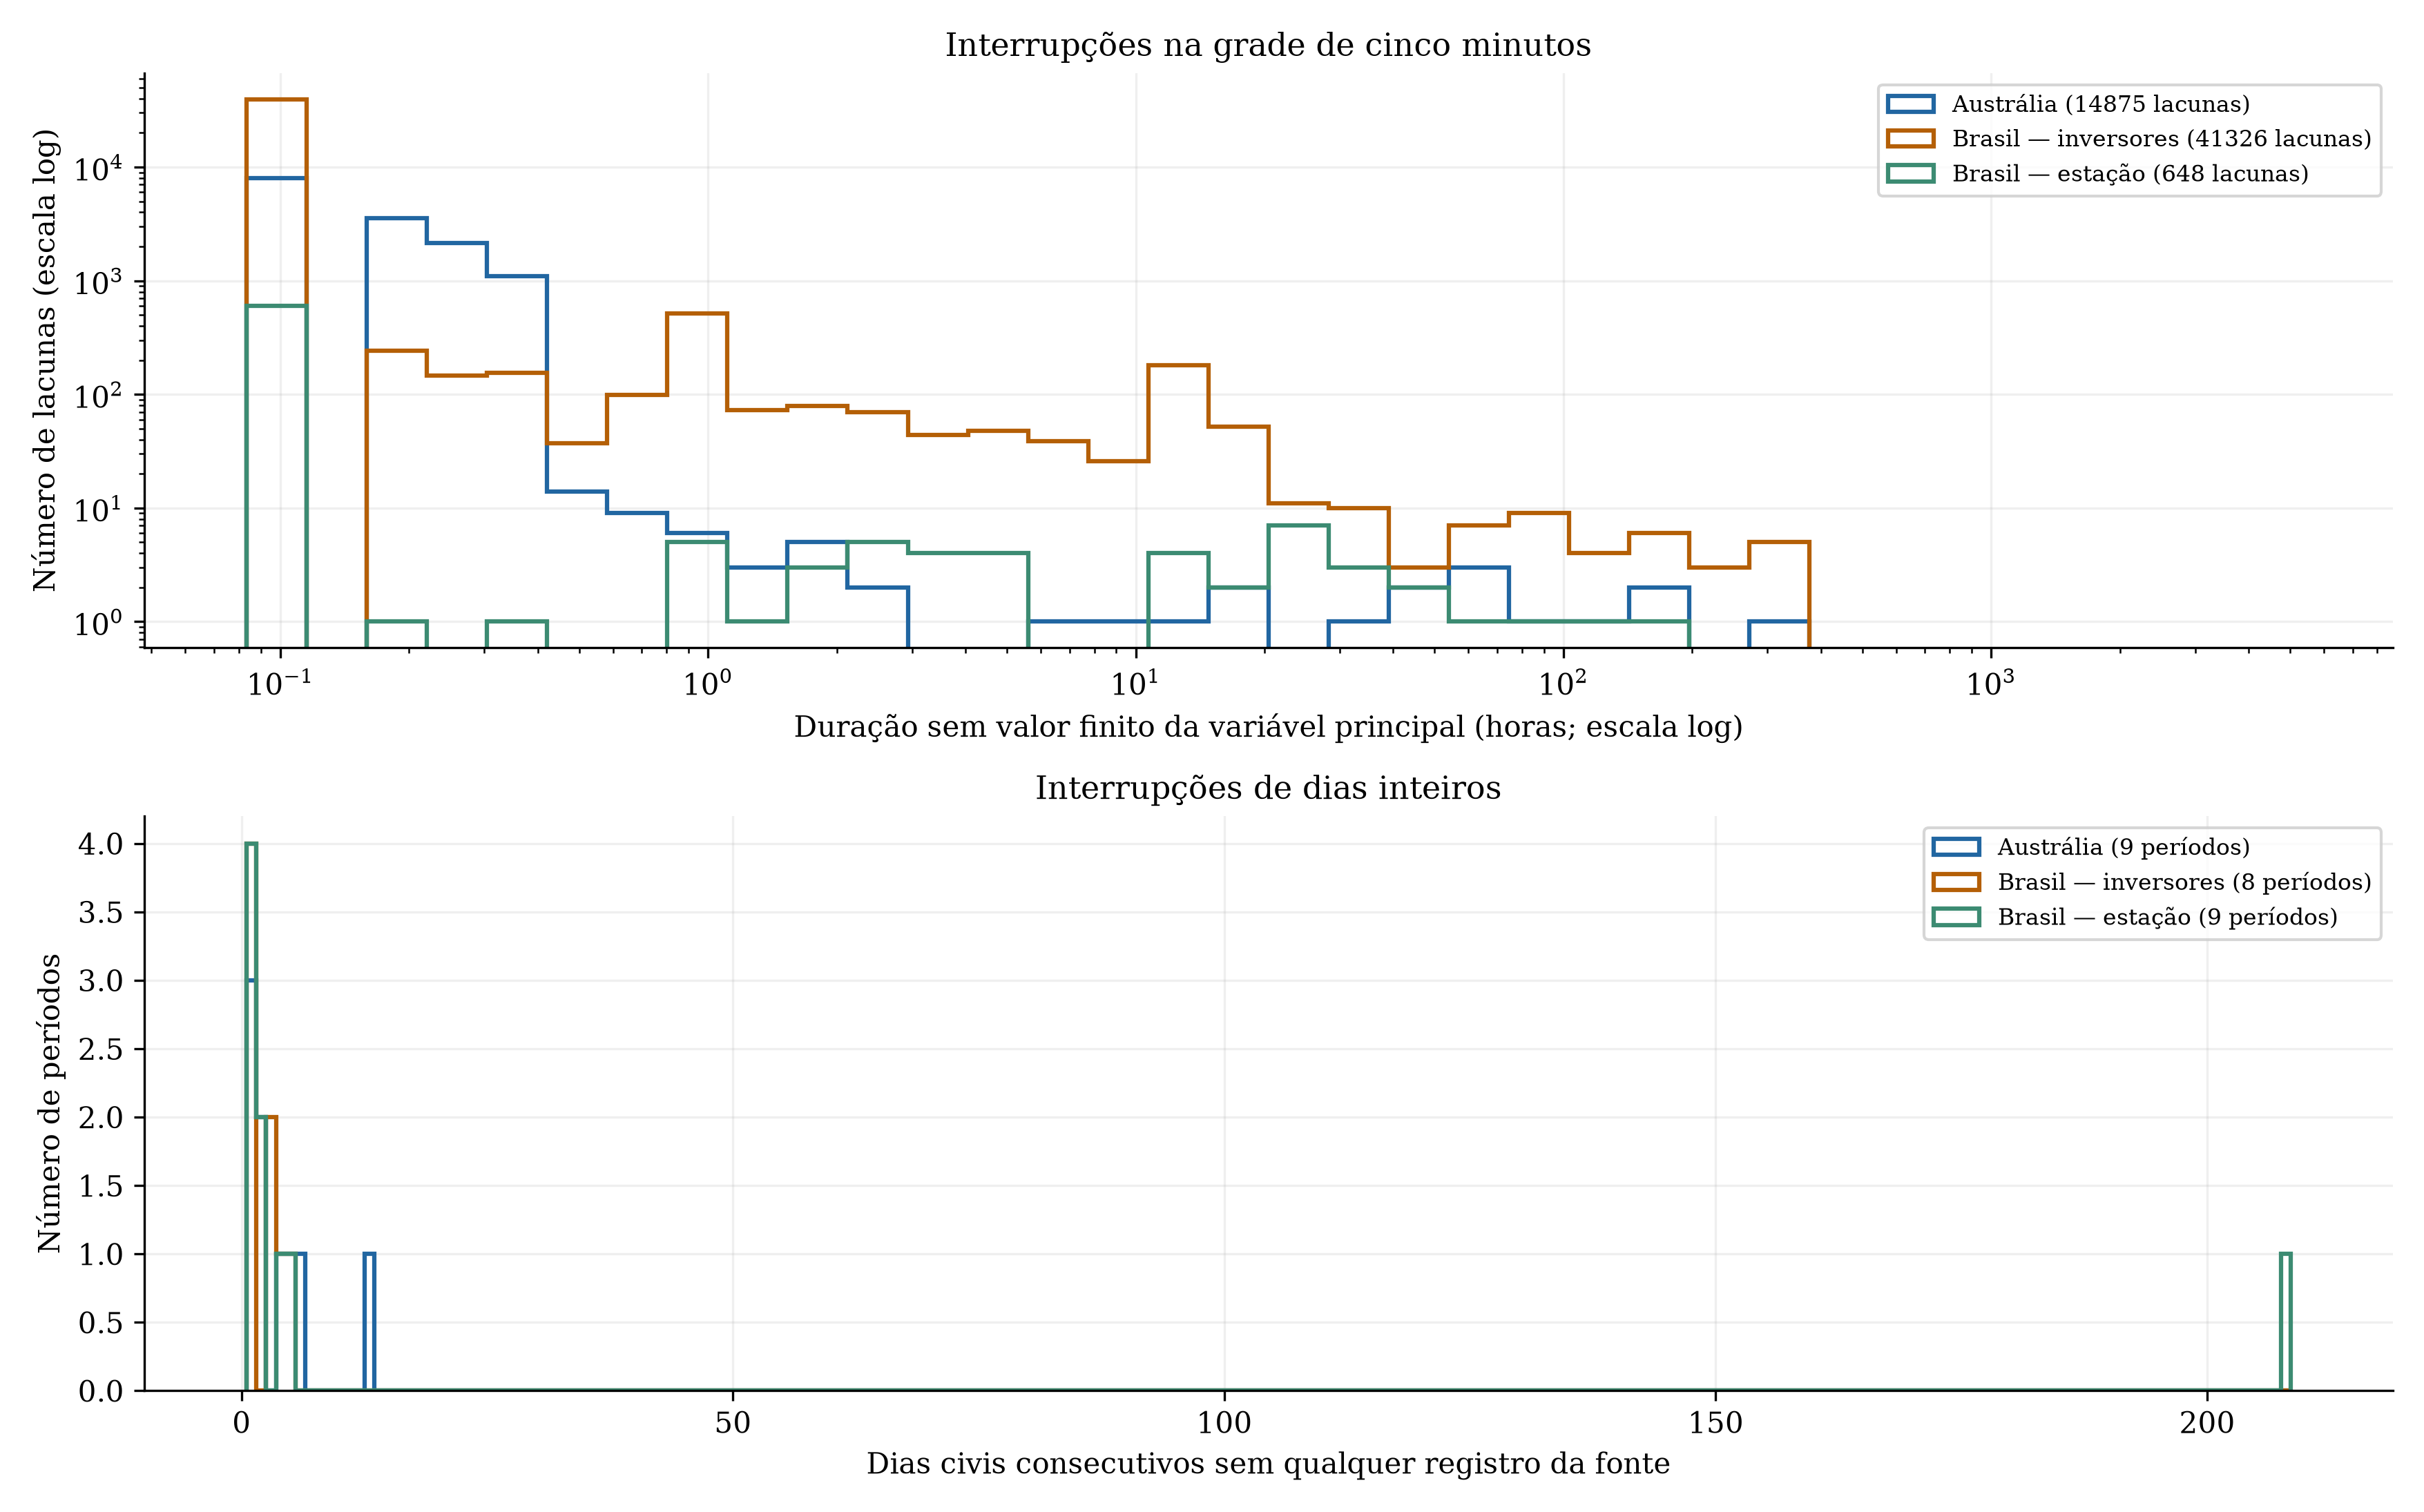

**Figura 3.2-08 — Duração das lacunas antes do tratamento.** No painel superior: intervalos [t,t+5min) sem valor finito de potência australiana, potência por inversor brasileiro e temperatura da estação. Cada inversor tem sua própria sequência; as contagens de oito sequências não são diretamente comparáveis às de uma estação. Duração = número de intervalos ausentes × cinco minutos. No inferior, conta-se ausência de todos os registros da fonte, inclusive fora dos minutos exatos. Bordas do calendário estão incluídas; não se interpreta lacuna como falha física comprovada.

Fonte: elaboração própria com os arquivos originais identificados no manifesto.

In [10]:
lacunas = tabelas["lacunas"]
lacunas_dia = tabelas["lacunas_dia"]
print("20 maiores lacunas de cinco minutos:")
display(lacunas.sort_values("minutos", ascending=False).head(20))
print("Períodos de dias inteiros sem qualquer registro:")
display(lacunas_dia.sort_values(["fonte", "inicio"]))
figura(8)

### Inspeção de dias específicos

Edite `FONTE`, `INICIO` e `FIM` para consultar as contagens diárias de outro período. As tabelas completas por dia já estão exportadas em CSV. `linhas_no_calendario` conserva a multiplicidade das linhas; `posicoes_com_registro` conta uma presença por intervalo e equipamento. Sua diferença corresponde a linhas adicionais dentro do mesmo intervalo, que podem ter timestamps distintos e não devem ser confundidas com duplicatas de chave exata.

O acesso a `fontes[FONTE]["bruto"]` permite conferir os valores originais selecionados. Esse DataFrame mantém a ordem e os valores lidos do CSV; campos auxiliares de horário e medidas de auditoria ficam separados.

In [11]:
FONTE = "brasil_inversores"  # "australia", "brasil_inversores" ou "brasil_estacao"
INICIO, FIM = "2025-01-01", "2025-02-05"
display(fontes[FONTE]["diario"].loc[INICIO:FIM])
# Exemplo de consulta aos registros crus de um dia, sem alterar o DataFrame:
DIA = "2025-01-30"
mascara_dia = fontes[FONTE]["instantes"].dt.normalize().eq(pd.Timestamp(DIA))
display(fontes[FONTE]["bruto"].loc[mascara_dia].head(12))

,posicoes_esperadas,linhas_no_calendario,posicoes_com_registro_exato,cobertura_registro_exato_pct,posicoes_com_registro,cobertura_registro_pct,posicoes_com_total_active_power_w,cobertura_total_active_power_w_pct,posicoes_com_daily_power_yields_kwh,cobertura_daily_power_yields_kwh_pct,posicoes_com_total_power_yields_kwh,cobertura_total_power_yields_kwh_pct,linhas_adicionais_no_intervalo,cobertura_todos_equipamentos_pct,linhas_duplicadas_chave_exata
data,,,,,,,,,,,,,,,
2025-01-01,2304,0,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0
2025-01-02,2304,1,0,0.000,1,0.043,1,0.043,1,0.043,1,0.043,0,0.000,0
2025-01-03,2304,0,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0
2025-01-04,2304,26,0,0.000,26,1.128,26,1.128,26,1.128,26,1.128,0,1.042,0
2025-01-05,2304,0,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0
2025-01-06,2304,267,0,0.000,267,11.589,267,11.589,267,11.589,267,11.589,0,10.764,0
2025-01-07,2304,1,0,0.000,1,0.043,1,0.043,1,0.043,1,0.043,0,0.000,0
2025-01-08,2304,0,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0
2025-01-09,2304,0,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0,0.000,0


,datetime,daily_power_yields_kwh,total_active_power_w,total_power_yields_kwh,usine_code,equipment_name
728245,2025-01-31T02:28:16.925Z,715.600,0.000,212468.000,07-07FX,inverter121
728379,2025-01-31T00:05:50.745Z,705.200,0.000,199934.000,07-07FX,inverter122
728399,2025-01-31T02:18:46.150Z,715.600,0.000,212468.000,07-07FX,inverter121
728478,2025-01-31T02:03:39.212Z,659.100,0.000,26790.000,07-07FX,inverter125
728531,2025-01-31T01:48:43.835Z,666.600,0.000,175731.000,07-07FX,inverter123
728621,2025-01-31T02:48:19.207Z,705.200,0.000,199934.000,07-07FX,inverter122
728635,2025-01-31T01:58:45.667Z,715.600,0.000,212468.000,07-07FX,inverter121
728699,2025-01-31T02:48:19.207Z,666.600,0.000,175731.000,07-07FX,inverter123
728702,2025-01-30T22:01:40.889Z,631.500,0.000,188256.000,07-07FX,inverter124
728703,2025-01-30T22:16:54.838Z,631.500,0.000,188256.000,07-07FX,inverter124


### Texto descritivo de apoio ao TCC e limites

A célula seguinte produz um parágrafo com as contagens efetivamente obtidas. Ele descreve disponibilidade, sem afirmar que a imputação é necessária ou que as ausências tenham uma causa conhecida. As escolhas de tratamento e seus efeitos pertencem à etapa metodológica posterior.

A ocorrência de dados duplicados, campos vazios ou valores extremos não permite atribuir toda a diferença entre modelos à qualidade dos dados. Nesta auditoria não se avalia desempenho preditivo, não se aprovam alvos e não se mede ganho com transfer learning.

In [12]:
paragrafos = []
for d in fontes.values():
    m = d["meta"]
    paragrafos.append(
        f"**{m['fonte']}:** no calendário de {m['inicio_calendario']} a {m['fim_calendario']}, "
        f"foram identificados {m['dias_sem_qualquer_registro']} dias sem qualquer registro, "
        f"{m['dias_com_registros_parciais']} dias com cobertura parcial e "
        f"{m['dias_com_grade_completa']} dias com todos os intervalos de coleta presentes. "
        f"Na seleção original, {m['chaves_repetidas']} chaves se repetem, com "
        f"{m['linhas_excedentes_mesma_chave']} linhas além da primeira. "
        "Essas contagens usam dias civis completos e incluem as bordas da aquisição.")
display(Markdown("\n\n".join(paragrafos)))

# Conferências de coerência das contagens, sem modificar as fontes.
for d in fontes.values():
    t = d["taxas"]
    assert (t.sem_registro + t.registro_sem_valor_finito + t.com_valor_finito == t.esperados).all()
    assert d["diario"].cobertura_registro_pct.between(0, 100).all()
    assert d["meta"]["dias_sem_qualquer_registro"] + d["meta"]["dias_com_registros_parciais"] + d["meta"]["dias_com_grade_completa"] == d["meta"]["dias_calendario"]
print("Conferências de denominadores e contagens: OK")
print("Legendas propostas:", PASTA / "legendas_figuras.md")
print("CSV diários e estatísticas:", auditoria["tabelas_dir"])
print("Fontes e hashes SHA-256:", PASTA / "manifesto.json")

Conferências de denominadores e contagens: OK
Legendas propostas: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\caracterizacao_dados_crus\legendas_figuras.md
CSV diários e estatísticas: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\caracterizacao_dados_crus\tabelas
Fontes e hashes SHA-256: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\caracterizacao_dados_crus\manifesto.json


**Austrália:** no calendário de 2013-07-25 a 2025-08-23, foram identificados 35 dias sem qualquer registro, 202 dias com cobertura parcial e 4176 dias com todos os intervalos de coleta presentes. Na seleção original, 0 chaves se repetem, com 0 linhas além da primeira. Essas contagens usam dias civis completos e incluem as bordas da aquisição.

**Brasil — inversores:** no calendário de 2025-01-01 a 2025-12-31, foram identificados 19 dias sem qualquer registro, 340 dias com cobertura parcial e 6 dias com todos os intervalos de coleta presentes. Na seleção original, 7732 chaves se repetem, com 27422 linhas além da primeira. Essas contagens usam dias civis completos e incluem as bordas da aquisição.

**Brasil — estação:** no calendário de 2025-01-01 a 2025-12-31, foram identificados 225 dias sem qualquer registro, 140 dias com cobertura parcial e 0 dias com todos os intervalos de coleta presentes. Na seleção original, 250 chaves se repetem, com 2144 linhas além da primeira. Essas contagens usam dias civis completos e incluem as bordas da aquisição.

### Arquivos para a redação

- `reports/tcc/caracterizacao_dados_crus/figuras/`: nove figuras em PNG (300 dpi) e PDF vetorial.
- `reports/tcc/caracterizacao_dados_crus/legendas_figuras.md`: legendas sugeridas e ressalvas de interpretação.
- `reports/tcc/caracterizacao_dados_crus/tabelas/`: inventário de todas as colunas, estatísticas dos campos selecionados, disponibilidade diária/mensal, lacunas, duplicatas e faixas de triagem.
- `reports/tcc/caracterizacao_dados_crus/manifesto.json`: escopo, convenções e hashes dos três CSVs originais.
- `src/energia_transfer/caracterizacao_bases_tcc.py`: implementação das contagens e figuras, para rastreabilidade.

As figuras são numeradas provisoriamente para a seção 3.2; a numeração final e a redação da fonte devem seguir as normas do TCC.